<img src = "https://drive.google.com/uc?export=view&id=1kl2OFnF2FADAAKjgZUFPo8dsBQUSIJM7" alt = "Encabezado MLDS" width = "100%">  </img>

# Clasificación visual de residuos con aprendizaje profundo
## Fase 2 · Entendimiento y preparación de los datos

**Proyecto aplicado · Módulo 5 · Machine Learning & Data Science**
**Universidad Nacional de Colombia**
**Fecha de entrega:** 22 de octubre de 2026

| Integrante | Nombre | Rol en esta fase |
|---|---|---|
| A | Juan Carlos Andrade Unigarro | Lidera: exploración, calidad y trazabilidad |
| B | Natalia Patricia Remolina Rodriguez | Pipeline de imágenes, aumentos y revisión cruzada |


## Resumen ejecutivo
---

| Aspecto | Hallazgo | Decisión |
|---|---|---|
| **Integridad** | 2.527 imágenes JPEG RGB de 512 × 384 en 6 clases; 0 ilegibles, 0 faltantes y codificación homogénea | Sin acción; los controles quedan automatizados |
| **Exclusiones** | 6 archivos con etiquetas en conflicto (identificados en la fase 1) | Se excluyen: quedan **2.521 imágenes utilizables** |
| **Partición** | Recalcularla con scikit-learn 1.9.1 cambiaría 1.165 asignaciones respecto de la fase 1 | Listas de validación y prueba fijadas explícitamente: la partición no depende de la versión |
| **Casi duplicados** | 79 pares de la misma clase con distancia pHash ≤ 10; 21 grupos cruzaban particiones | 26 imágenes pasan a entrenamiento. Partición final: **1.798 / 360 / 363** |
| **Desbalance** | Razón 4,32 : 1 (`paper` 23,5 %, `trash` 5,5 %) | F1 macro, recall por clase y pesos por clase (`trash`: 3,06) |
| **Atajo de fondo** | Solo el borde de la foto alcanza F1 macro **0,403** en validación | Aumento de ganancia por canal y análisis de errores según el fondo |
| **Atípicos** | 98 imágenes de entrenamiento (5,5 %) con exposición, nitidez o contenido extremos | Se conservan y se marcan en el manifiesto |
| **Preprocesamiento** | Reducción a 160 × 120 (Lanczos) y relleno hasta 160 × 160; caché de 145 MB; `tf.data` con aumentos solo en entrenamiento | 1,7× más rápido que leer los JPEG en cada época; escala [0, 1] (CNN) y [−1, 1] (MobileNetV2) |
| **Referencia a superar** | Mejor línea base sin aprendizaje profundo: F1 macro **0,528** en validación | Las redes de la fase 3 deben superarla con claridad |
| **Controles** | 14 de 14 controles automáticos en OK | La prueba sigue reservada para la fase 5 |

## Contenido
---

0. **Continuidad con la fase 1 y carga de los datos:** entorno, descarga verificada, inspección y reconstrucción de la partición
1. **Análisis exploratorio:** resumen general · calidad y duplicados · tipos de variables y distribución · relación entre variables · valores atípicos
2. **Limpieza y preparación:** decisiones · redimensionado · caché · pipeline `tf.data` y aumentos · verificación · eficiencia · pesos por clase
3. **Líneas base en validación**
4. **Controles automáticos y trazabilidad**
5. **Conclusiones y próximos pasos**
6. **Referencias**


## 0. Continuidad con la fase 1 y carga de los datos
---

La fase 1 dejó fijadas cuatro decisiones que esta entrega reutiliza sin cambios, salvo la corrección documentada en la sección 1.2:

1. **Fuente:** TrashNet, versión reducida (`dataset-resized.zip`), revisión fijada en Hugging Face y verificada con SHA-256.
2. **Exclusión:** 3 pares de archivos con píxeles idénticos y etiquetas distintas (6 archivos) se apartan; quedan **2.521 imágenes utilizables**.
3. **Particiones:** 70 % entrenamiento, 15 % validación y 15 % prueba, estratificadas por clase y sin separar imágenes perceptualmente similares (distancia pHash ≤ 4), con semilla 42.
4. **Protocolo:** la exploración y las decisiones se apoyan en **entrenamiento**; validación sirve para comparar alternativas; prueba solo se consulta al final.

**Qué se agrega en la fase 2:** descriptores visuales por imagen, análisis de su relación con la clase, revisión de casi duplicados con un umbral más amplio, tratamiento de atípicos, pipeline de entrada para Keras, pesos por clase y líneas base.

### 0.1 Entorno

In [1]:
# @title 0.1 Entorno: librerías, semilla y versiones
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime, timezone
import hashlib
import importlib.metadata as metadata
import io
import json
import os
import platform
import re
import shutil
import subprocess
import sys
import time
import urllib.request
import zipfile

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from PIL import Image, JpegImagePlugin
from scipy import ndimage, stats
from scipy.fft import dctn
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display, Markdown

try:
    import tensorflow as tf
except ImportError:  # Colab ya incluye TensorFlow; en otro entorno se instala una sola vez.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow"], check=True)
    import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
LABEL_ES = dict(zip(CLASSES, ["Cartón", "Vidrio", "Metal", "Papel", "Plástico", "Residual"]))
EXPECTED = {"cardboard": 403, "glass": 501, "metal": 410, "paper": 594, "plastic": 482, "trash": 137}
SPLITS = ["entrenamiento", "validacion", "prueba"]
SPLIT_ES = {"entrenamiento": "Entrenamiento", "validacion": "Validación", "prueba": "Prueba"}

ROOT = Path.cwd() / "residuos_fase2"
ARCHIVE = ROOT / "dataset-resized.zip"
DATA_DIR = ROOT / "imagenes"
REPORT_DIR = ROOT / "reportes"
for folder in (ROOT, DATA_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Paleta categórica en orden fijo (validada para daltonismo) y tintas neutras para texto y ejes.
CLASS_COLORS = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
SPLIT_COLORS = dict(zip(SPLITS, ["#2a78d6", "#eb6834", "#1baf7a"]))
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
DIVERGING = LinearSegmentedColormap.from_list("divergente", ["#2a78d6", "#f0efec", "#eb6834"])
SEQUENTIAL = LinearSegmentedColormap.from_list("secuencial", ["#f4f8fd", "#86b6ef", "#104281"])
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "figure.facecolor": "white", "axes.facecolor": "white",
})


def miles(n):
    """Entero con punto como separador de miles."""
    return f"{int(n):,}".replace(",", ".")


def dec(x, nd=2):
    """Número con coma decimal, como en el texto en español."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".")


def pct(x, nd=1):
    """Proporción (0-1) expresada como porcentaje con coma decimal."""
    return dec(100 * x, nd) + " %"


versions = {p: metadata.version(p) for p in
            ["numpy", "pandas", "Pillow", "scipy", "scikit-learn", "matplotlib"]}
versions["tensorflow"] = tf.__version__
print("Python:", platform.python_version(), "| Semilla:", SEED, "| Núcleos de CPU:", os.cpu_count())
print("GPU visible para TensorFlow:", tf.config.list_physical_devices("GPU") or "ninguna (esta fase no la necesita)")
display(pd.Series(versions, name="versión").to_frame())

Python: 3.13.17 | Semilla: 42 | Núcleos de CPU: 2
GPU visible para TensorFlow: ninguna (esta fase no la necesita)


,versión
numpy,2.5.3
pandas,3.0.5
Pillow,12.3.0
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.11.2
tensorflow,2.21.0


### 0.2 Adquisición verificada

Se mantiene la fuente de la fase 1 (Hugging Face, revisión fijada). Se agrega como **respaldo** el mismo ZIP publicado por el autor en GitHub, fijado a un commit y con su propio SHA-256: ambos ZIP difieren en bytes como contenedor, pero al preparar esta fase se comprobó que contienen las mismas imágenes. Además, la sección 0.4 verifica en cada ejecución, sea cual sea la fuente usada, que el contenido coincide con lo auditado en la fase 1 (mismos conteos, los mismos 3 conflictos con los mismos hashes de archivo, los mismos 28 pares similares y la misma partición). Así una caída de una de las fuentes no bloquea la ejecución. Solo se extraen las imágenes de las seis carpetas esperadas; los metadatos de macOS (`__MACOSX`, `.DS_Store`) se ignoran.

In [2]:
# @title 0.2 Descarga verificada (Hugging Face, con respaldo en GitHub)
HF_REVISION = "94cd17ebfd6702bf62281d3c89f22ff649815b46"
GH_COMMIT = "6fa2b878c6c1b4304b91109070ce0edf9279bb31"
SOURCES = [
    {"nombre": "Hugging Face · revisión fijada en la fase 1",
     "url": f"https://huggingface.co/datasets/garythung/trashnet/resolve/{HF_REVISION}/dataset-resized.zip",
     "sha256": "c060e8abfe5d6de0578ca15be1ed8ad0794a865d333c3473d53d1d9ad6e38b8c"},
    {"nombre": "GitHub del autor · commit fijado (respaldo)",
     "url": f"https://github.com/garythung/trashnet/raw/{GH_COMMIT}/data/dataset-resized.zip",
     "sha256": "0bf472790f8b20e5c950d5b5012a9d38af0d3392efd65f8ce171334fc16b07c2"},
]


def sha256_file(path):
    """Hash por bloques para mantener bajo el uso de memoria."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def obtain_archive(sources, destination):
    """Reutiliza una caché verificada o descarga de la primera fuente disponible."""
    if destination.exists():
        digest = sha256_file(destination)
        for source in sources:
            if digest == source["sha256"]:
                return source, "caché verificada"
    errors = []
    for source in sources:
        temporary = destination.with_suffix(".download")
        try:
            with urllib.request.urlopen(source["url"], timeout=60) as response, temporary.open("wb") as target:
                shutil.copyfileobj(response, target, length=1024 * 1024)
            if sha256_file(temporary) != source["sha256"]:
                raise ValueError("el SHA-256 no coincide con el fijado")
            temporary.replace(destination)
            return source, "descarga verificada"
        except Exception as exc:
            temporary.unlink(missing_ok=True)
            errors.append(f"{source['nombre']}: {type(exc).__name__}")
    raise RuntimeError("No se obtuvo un ZIP válido. " + " | ".join(errors))


t0 = time.perf_counter()
source, acquisition_status = obtain_archive(SOURCES, ARCHIVE)
manifest_names = []
with zipfile.ZipFile(ARCHIVE) as archive:
    zip_entries = len(archive.infolist())
    for member in archive.infolist():
        parts = Path(member.filename).parts
        if (len(parts) == 3 and parts[0] == "dataset-resized"
                and parts[1] in CLASSES and parts[2].lower().endswith(".jpg")):
            relative = Path(parts[1]) / parts[2]
            target = DATA_DIR / relative
            target.parent.mkdir(exist_ok=True)
            with archive.open(member) as src, target.open("wb") as dst:
                shutil.copyfileobj(src, dst)
            manifest_names.append(relative.as_posix())

manifest_names = sorted(manifest_names)
assert len(manifest_names) == len(set(manifest_names)), "Rutas duplicadas dentro del ZIP."
extracted_bytes = sum((DATA_DIR / name).stat().st_size for name in manifest_names)
print("Fuente:", source["nombre"], "|", acquisition_status)
print("ZIP:", f"{ARCHIVE.stat().st_size / 1e6:.2f} MB", "| entradas en el ZIP:", zip_entries)
print("Imágenes extraídas:", len(manifest_names), f"| {extracted_bytes / 1e6:.2f} MB en disco")
print("Tiempo de adquisición y extracción:", f"{time.perf_counter() - t0:.1f} s")

Fuente: GitHub del autor · commit fijado (respaldo) | caché verificada
ZIP: 42.83 MB | entradas en el ZIP: 2540
Imágenes extraídas: 2527 | 43.28 MB en disco
Tiempo de adquisición y extracción: 1.2 s


### 0.3 Inspección de todas las imágenes en una sola lectura

Cada imagen se decodifica **una vez** y en paralelo (hilos de CPU). De esa lectura salen tres productos:

- **Controles de integridad y codificación:** decodificación, dimensiones, modo de color, orientación EXIF, perfil ICC, submuestreo de color, tablas de cuantización JPEG, hash de bytes, hash de píxeles y hash perceptual (el mismo de la fase 1).
- **Descriptores visuales** calculados a media resolución (256 × 192), suficientes para estadísticas globales y cuatro veces más baratos. Se definen en la sección 1.3. **No son entradas del modelo**: sirven para entender los datos y vigilar atajos.
- **Miniaturas** (96 × 72) de la imagen y de su mapa de bordes, para construir imágenes promedio por clase.

Los descriptores se calculan para todas las imágenes porque quedarán en el manifiesto para el análisis de errores de la fase 5, pero **los estadísticos y las decisiones de esta fase usan solo entrenamiento**.

In [3]:
# @title 0.3 Inspección de todas las imágenes: integridad, descriptores y miniaturas
THUMB_WH = (96, 72)   # ancho, alto de las miniaturas
BORDER = 8            # franja del borde a media resolución = 16 px de la imagen original
LATERAL = 32          # franja lateral a media resolución = 64 px que eliminaría un recorte central cuadrado


def perceptual_hash(rgb):
    """Huella de baja frecuencia (idéntica a la fase 1): DCT 32×32, bloque 8×8 y umbral mediano."""
    gray = np.asarray(rgb.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    low_frequency = dctn(gray, type=2, norm="ortho")[:8, :8].ravel()
    bits = low_frequency > np.median(low_frequency[1:])
    bits[0] = False
    return int.from_bytes(np.packbits(bits).tobytes(), "big")


def describe_pixels(rgb):
    """Descriptores globales a media resolución; devuelve también miniaturas para promedios."""
    small = rgb.reduce(2)
    a = np.asarray(small, dtype=np.float32)
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    lum = 0.299 * r + 0.587 * g + 0.114 * b
    sat = np.asarray(small.convert("HSV"), dtype=np.float32)[..., 1] / 255
    rg, yb = r - g, 0.5 * (r + g) - b
    hist = np.bincount(np.clip(lum, 0, 255).astype(np.uint8).ravel(), minlength=256) / lum.size
    nonzero = hist[hist > 0]
    ring = np.ones(lum.shape, bool)
    ring[BORDER:-BORDER, BORDER:-BORDER] = False
    grad = np.hypot(ndimage.sobel(lum, axis=1), ndimage.sobel(lum, axis=0))
    lateral = grad[:, :LATERAL].sum() + grad[:, -LATERAL:].sum()
    features = {
        "brillo": lum.mean(),
        "contraste": lum.std(),
        "saturacion": 100 * sat.mean(),
        "colorido": np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()),
        "nitidez": np.log10(ndimage.laplace(lum).var() + 1e-6),
        "entropia": -(nonzero * np.log2(nonzero)).sum(),
        "sobreexpuesta": 100 * (lum >= 250).mean(),
        "oscura": 100 * (lum < 40).mean(),
        "borde_brillo": lum[ring].mean(),
        "borde_calidez": (r - b)[ring].mean(),
        "borde_variacion": lum[ring].std(),
        "energia_lateral": 100 * lateral / max(grad.sum(), 1e-6),
        "media_R": r.mean(), "media_G": g.mean(), "media_B": b.mean(),
        "borde_R": r[ring].mean(), "borde_G": g[ring].mean(), "borde_B": b[ring].mean(),
    }
    thumb = np.asarray(small.resize(THUMB_WH, Image.Resampling.BOX), dtype=np.uint8)
    energy = np.asarray(Image.fromarray(grad).resize(THUMB_WH, Image.Resampling.BOX), dtype=np.float32)
    return {k: float(v) for k, v in features.items()}, thumb, energy


def inspect_image(relative):
    """Una lectura por imagen: integridad, codificación, hashes, descriptores y miniaturas."""
    path = DATA_DIR / relative
    row = {"ruta": relative, "clase": path.parent.name, "bytes": path.stat().st_size, "error": ""}
    thumb = energy = None
    try:
        data = path.read_bytes()
        with Image.open(io.BytesIO(data)) as image:
            image.load()
            row.update(
                ancho=image.width, alto=image.height, modo=image.mode, formato=image.format,
                orientacion_exif=int(image.getexif().get(0x0112, 0)),
                perfil_icc="icc_profile" in image.info,
                progresivo=bool(image.info.get("progressive", 0)),
                submuestreo={0: "4:4:4", 1: "4:2:2", 2: "4:2:0"}.get(JpegImagePlugin.get_sampling(image), "otro"),
                tablas_q=hashlib.md5(repr(getattr(image, "quantization", None)).encode()).hexdigest()[:8],
            )
            rgb = image.convert("RGB")
        row.update(sha256=hashlib.sha256(data).hexdigest(),
                   pixel_sha256=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(),
                   phash=f"{perceptual_hash(rgb):016x}")
        features, thumb, energy = describe_pixels(rgb)
        row.update(features)
    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
    return row, thumb, energy


t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:
    results = list(pool.map(inspect_image, manifest_names))
raw = pd.DataFrame([row for row, _, _ in results]).sort_values("ruta").reset_index(drop=True)
raw["kb"] = raw["bytes"] / 1024
THUMBS = {row["ruta"]: thumb for row, thumb, _ in results if thumb is not None}
ENERGY = {row["ruta"]: energy for row, _, energy in results if energy is not None}
del results
print(f"Imágenes inspeccionadas: {len(raw)} en {time.perf_counter() - t0:.1f} s "
      f"con {os.cpu_count()} hilos")
print("Columnas generadas por imagen:", raw.shape[1])

Imágenes inspeccionadas: 2527 en 14.7 s con 2 hilos
Columnas generadas por imagen: 35


### 0.4 Reconstrucción exacta de las decisiones de la fase 1

**Hallazgo de reproducibilidad.** La fase 1 advirtió que una actualización de bibliotecas podía alterar la partición aunque se mantuviera la semilla. Al preparar esta fase se comprobó: con la misma semilla y los mismos grupos, `StratifiedGroupKFold` de scikit-learn 1.6.1 (la versión de la fase 1) y de la 1.9.1 asignan particiones distintas a 1.165 de las 2.521 imágenes. Para que la partición **no dependa de la versión instalada**, la siguiente celda fija explícitamente los archivos de validación y prueba de la fase 1 (todo lo demás es entrenamiento). La celda posterior verifica que la tabla por clase coincide con la reportada en la fase 1 y calcula una huella SHA-256 de la asignación.


In [4]:
# @title Particiones de validación y prueba fijadas en la fase 1 { display-mode: "form" }
# Números de archivo por clase (por ejemplo, 12 en cardboard corresponde a cardboard/cardboard12.jpg).
# Generadas con scikit-learn 1.6.1, semilla 42; el resto de imágenes utilizables es entrenamiento.
PARTICION_FASE1 = {
    "validacion": {
        "cardboard": [
            1, 7, 19, 22, 28, 38, 39, 46, 47, 68, 73, 93, 95, 96, 100, 101, 102, 104, 121, 122, 140,
            145, 146, 164, 175, 176, 177, 189, 191, 192, 193, 195, 214, 234, 235, 238, 255, 257,
            259, 260, 265, 274, 285, 286, 301, 302, 303, 320, 327, 329, 340, 347, 348, 359, 366,
            369, 380, 389, 390, 393, 399
        ],
        "glass": [
            41, 43, 51, 52, 60, 63, 65, 66, 73, 82, 97, 114, 116, 118, 126, 131, 133, 134, 137, 140,
            157, 158, 164, 165, 182, 183, 200, 204, 206, 223, 225, 226, 227, 231, 239, 244, 245,
            247, 258, 270, 271, 294, 295, 296, 310, 315, 317, 318, 324, 332, 333, 336, 337, 356,
            362, 365, 366, 384, 385, 386, 409, 410, 420, 421, 424, 426, 430, 442, 452, 453, 472,
            473, 475, 495, 496, 500
        ],
        "metal": [
            9, 10, 44, 45, 46, 47, 49, 69, 70, 74, 87, 92, 114, 115, 116, 124, 134, 136, 138, 141,
            144, 150, 153, 156, 157, 182, 187, 188, 203, 206, 207, 229, 230, 232, 233, 237, 239,
            250, 252, 264, 275, 277, 279, 298, 300, 301, 316, 320, 321, 322, 323, 325, 341, 347,
            349, 370, 374, 375, 391, 392, 394, 410
        ],
        "paper": [
            3, 14, 24, 30, 39, 46, 61, 69, 77, 78, 80, 98, 113, 114, 116, 134, 136, 150, 151, 152,
            160, 161, 165, 189, 190, 192, 207, 214, 216, 224, 230, 232, 240, 249, 252, 255, 257,
            259, 272, 286, 302, 309, 321, 323, 328, 331, 334, 342, 343, 346, 365, 366, 368, 391,
            392, 393, 411, 415, 416, 433, 435, 440, 444, 450, 454, 456, 463, 483, 484, 485, 503,
            504, 505, 525, 529, 530, 531, 535, 539, 556, 558, 563, 585, 590, 591, 592
        ],
        "plastic": [
            27, 28, 30, 32, 34, 36, 43, 48, 52, 53, 62, 65, 69, 84, 90, 91, 100, 104, 112, 118, 124,
            140, 148, 149, 154, 167, 170, 171, 172, 177, 190, 192, 194, 206, 209, 216, 232, 233,
            235, 253, 254, 255, 269, 273, 279, 280, 300, 302, 321, 323, 341, 348, 362, 369, 383,
            384, 385, 401, 402, 403, 404, 407, 412, 426, 433, 448, 450, 455, 475, 476, 477
        ],
        "trash": [
            29, 30, 31, 32, 33, 37, 49, 53, 56, 58, 80, 82, 83, 106, 107, 108, 123, 124, 135
        ],
    },
    "prueba": {
        "cardboard": [
            3, 9, 14, 16, 23, 30, 43, 44, 45, 64, 65, 67, 87, 90, 103, 138, 139, 157, 162, 172, 183,
            184, 185, 186, 187, 210, 211, 212, 213, 231, 233, 246, 251, 254, 256, 258, 270, 278,
            280, 299, 314, 318, 324, 333, 338, 343, 345, 346, 353, 358, 367, 368, 378, 384, 387, 388
        ],
        "glass": [
            2, 5, 10, 18, 20, 22, 27, 31, 42, 45, 47, 50, 64, 68, 69, 94, 96, 99, 108, 109, 111,
            112, 113, 122, 130, 132, 149, 153, 155, 179, 181, 199, 201, 207, 211, 213, 218, 224,
            241, 243, 246, 260, 266, 285, 290, 292, 293, 311, 312, 313, 314, 331, 334, 335, 347,
            360, 361, 376, 378, 383, 388, 403, 405, 408, 413, 415, 416, 429, 449, 450, 468, 470,
            487, 491, 492, 494
        ],
        "metal": [
            1, 3, 23, 30, 32, 37, 39, 41, 59, 63, 68, 84, 85, 86, 90, 111, 112, 113, 131, 133, 135,
            137, 139, 140, 152, 168, 169, 179, 181, 185, 186, 202, 204, 213, 225, 226, 227, 228,
            251, 257, 261, 269, 273, 274, 278, 297, 311, 314, 318, 319, 339, 343, 345, 359, 363,
            380, 387, 390, 406, 407, 408, 409
        ],
        "paper": [
            32, 34, 48, 50, 56, 59, 65, 70, 73, 92, 96, 97, 105, 111, 112, 131, 135, 143, 148, 149,
            153, 158, 159, 181, 183, 188, 200, 202, 205, 209, 212, 215, 228, 239, 242, 246, 247,
            248, 268, 269, 270, 285, 297, 298, 299, 318, 319, 320, 327, 340, 341, 349, 353, 361,
            364, 386, 387, 388, 406, 407, 410, 413, 426, 430, 431, 436, 439, 443, 445, 455, 481,
            482, 496, 499, 500, 507, 519, 523, 526, 527, 528, 540, 561, 562, 575, 583, 584, 586, 587
        ],
        "plastic": [
            6, 16, 18, 23, 25, 29, 40, 45, 59, 61, 81, 83, 85, 89, 94, 105, 111, 123, 129, 137, 141,
            144, 146, 147, 164, 165, 185, 191, 203, 210, 212, 229, 230, 250, 251, 252, 261, 262,
            271, 276, 277, 297, 298, 316, 317, 319, 338, 339, 342, 354, 357, 364, 370, 374, 379,
            381, 393, 395, 396, 400, 422, 428, 429, 445, 446, 458, 460, 466, 470, 473, 474
        ],
        "trash": [
            19, 23, 27, 28, 48, 50, 54, 76, 77, 79, 81, 97, 103, 105, 120, 121, 126, 127, 133, 137
        ],
    },
}

In [5]:
# @title 0.4 Reconstrucción y verificación de la partición de la fase 1
POPCOUNT8 = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def hamming_matrix(hex_hashes):
    """Distancias de Hamming entre todas las huellas de 64 bits (vectorizado, sin bucles de Python)."""
    h = np.array([int(x, 16) for x in hex_hashes], dtype=np.uint64)
    xor = h[:, None] ^ h[None, :]
    return POPCOUNT8[xor.view(np.uint8)].reshape(xor.shape + (8,)).sum(axis=-1, dtype=np.uint8)


def component_labels(paths, edges):
    """Componentes conectados; cada grupo se nombra con su ruta menor (convención de la fase 1)."""
    index = {path: k for k, path in enumerate(paths)}
    rows = [index[a] for a, b in edges]
    cols = [index[b] for a, b in edges]
    graph = coo_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(paths), len(paths)))
    _, labels = connected_components(graph, directed=False)
    names = pd.Series(paths).groupby(labels).transform("min")
    return names.to_numpy()


# Exclusiones de la fase 1
valid = raw.loc[raw["error"].eq("")].copy()
labels_per_pixel_hash = valid.groupby("pixel_sha256")["clase"].nunique()
conflict_hashes = set(labels_per_pixel_hash[labels_per_pixel_hash > 1].index)
conflicts = valid.loc[valid["pixel_sha256"].isin(conflict_hashes)]
eligible = valid.loc[~valid["pixel_sha256"].isin(conflict_hashes)]
usable = eligible.drop_duplicates("pixel_sha256", keep="first").reset_index(drop=True)

# Pares similares de la fase 1 (umbral 4, sobre todas las imágenes legibles)
PHASH_THRESHOLD_F1 = 4
dist_valid = hamming_matrix(valid["phash"])
iv, jv = np.triu_indices(len(valid), k=1)
close = dist_valid[iv, jv] <= PHASH_THRESHOLD_F1
pairs_f1 = pd.DataFrame({"ruta_a": valid["ruta"].to_numpy()[iv[close]],
                         "ruta_b": valid["ruta"].to_numpy()[jv[close]],
                         "distancia": dist_valid[iv, jv][close]})
del dist_valid, iv, jv, close
usable_set = set(usable["ruta"])
edges_f1 = [(a, b) for a, b in zip(pairs_f1["ruta_a"], pairs_f1["ruta_b"]) if a in usable_set and b in usable_set]
usable["grupo_fase1"] = component_labels(usable["ruta"].tolist(), edges_f1)

# Partición fijada de la fase 1
assigned = {f"{label}/{label}{number}.jpg": split
            for split, by_class in PARTICION_FASE1.items()
            for label, numbers in by_class.items() for number in numbers}
usable["particion_fase1"] = usable["ruta"].map(assigned).fillna("entrenamiento")
phase1_table = pd.crosstab(usable["clase"], usable["particion_fase1"]).reindex(index=CLASSES, columns=SPLITS)
FASE1_REPORTADA = pd.DataFrame({"entrenamiento": [286, 346, 285, 419, 338, 98],
                                "validacion": [61, 76, 62, 86, 71, 19],
                                "prueba": [56, 76, 62, 89, 71, 20]}, index=CLASSES)
FASE1_HUELLA = "b374e83e6d7169f8e81cdbf7ce078e3214d4955d96e547d92bd784099d0ccd0f"
huella = hashlib.sha256("\n".join(sorted(usable["ruta"] + "," + usable["particion_fase1"])).encode()).hexdigest()

# ¿Qué haría la versión instalada de scikit-learn si se recalculara la partición?
splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
fold = np.full(len(usable), -1)
for k, (_, holdout) in enumerate(splitter.split(np.zeros((len(usable), 1)), usable["clase"], usable["grupo_fase1"])):
    fold[holdout] = k
recomputed = np.select([fold < 3, fold < 6], ["prueba", "validacion"], default="entrenamiento")
changed_by_version = int((recomputed != usable["particion_fase1"]).sum())

conflict_files = sorted(conflicts["ruta"])
checks_f1 = {
    "Conteos por clase iguales a la fuente (2.527)": raw["clase"].value_counts().to_dict() == EXPECTED,
    "Mismos 6 archivos en conflicto que la fase 1": conflict_files == [
        "glass/glass115.jpg", "glass/glass176.jpg", "glass/glass389.jpg",
        "metal/metal91.jpg", "plastic/plastic152.jpg", "plastic/plastic332.jpg"],
    "Hashes de archivo de los conflictos iguales a los impresos en la fase 1": all(
        valid.set_index("ruta").loc[f"glass/glass{n}.jpg", "sha256"].startswith(prefix)
        for n, prefix in [(115, "81546d1362d75fc6"), (176, "c41b99aec8a3257c"), (389, "e971f4f8f50e960e")]),
    "Mismos 28 pares similares (pHash ≤ 4)": len(pairs_f1) == 28,
    "2.521 imágenes utilizables": len(usable) == 2521,
    "Tabla por clase y partición igual a la fase 1": phase1_table.equals(FASE1_REPORTADA),
    "Huella de la asignación igual a la registrada": huella == FASE1_HUELLA,
    "Ningún grupo de la fase 1 cruza particiones": usable.groupby("grupo_fase1")["particion_fase1"].nunique().max() == 1,
}
display(pd.DataFrame({"control": checks_f1.keys(),
                      "resultado": ["OK" if ok else "REVISAR" for ok in checks_f1.values()]}))
assert all(checks_f1.values()), "La reconstrucción de la fase 1 no coincide: revise antes de continuar."
display(phase1_table.rename(index=LABEL_ES, columns=SPLIT_ES).assign(Total=lambda t: t.sum(axis=1)))
print(f"Con scikit-learn {versions['scikit-learn']}, recalcular StratifiedGroupKFold cambiaría "
      f"{changed_by_version} de {len(usable)} asignaciones respecto de la fase 1"
      + (" (la lista fijada evita esa deriva)." if changed_by_version else " (misma asignación)."))

,control,resultado
0,Conteos por clase iguales a la fuente (2.527),OK
1,Mismos 6 archivos en conflicto que la fase 1,OK
2,Hashes de archivo de los conflictos iguales a ...,OK
3,Mismos 28 pares similares (pHash ≤ 4),OK
4,2.521 imágenes utilizables,OK
5,Tabla por clase y partición igual a la fase 1,OK
6,Huella de la asignación igual a la registrada,OK
7,Ningún grupo de la fase 1 cruza particiones,OK


particion_fase1,Entrenamiento,Validación,Prueba,Total
clase,,,,
Cartón,286,61,56,403
Vidrio,346,76,76,498
Metal,285,62,62,409
Papel,419,86,89,594
Plástico,338,71,71,480
Residual,98,19,20,137


Con scikit-learn 1.9.1, recalcular StratifiedGroupKFold cambiaría 1165 de 2521 asignaciones respecto de la fase 1 (la lista fijada evita esa deriva).


## 1. Análisis exploratorio de los datos
---

**Unidad de análisis:** una fotografía. **Qué se usa en cada parte:** el inventario, la calidad y los duplicados se revisan en todo el conjunto, porque son controles de integridad y no influyen en el modelo; la distribución de etiquetas se reporta por partición; las estadísticas descriptivas, correlaciones y umbrales de atípicos se calculan **solo con entrenamiento**.

### 1.1. Resumen general
---

- ¿Cuántos documentos tiene el dataset?
- ¿En qué formato están guardados los datos?
- ¿Qué tamaño en MB tiene el conjunto?

In [6]:
# @title 1.1 Inventario por clase y resumen general
per_class = raw.groupby("clase").agg(imagenes=("ruta", "size"), MB=("bytes", lambda s: s.sum() / 1e6),
                                      KB_medio=("kb", "mean"), KB_min=("kb", "min"), KB_max=("kb", "max"))
per_class = per_class.reindex(CLASSES)
per_class.insert(1, "porcentaje", 100 * per_class["imagenes"] / per_class["imagenes"].sum())
per_class.loc["Total"] = [per_class["imagenes"].sum(), 100.0, per_class["MB"].sum(),
                          raw["kb"].mean(), raw["kb"].min(), raw["kb"].max()]
per_class["imagenes"] = per_class["imagenes"].astype(int)
display(per_class.rename(index=LABEL_ES | {"Total": "Total"}).round(2))

general = pd.DataFrame({"Valor": {
    "Imágenes (documentos)": miles(len(raw)),
    "Clases (carpetas)": f"{raw['clase'].nunique()}: " + ", ".join(CLASSES),
    "Estructura": "dataset-resized/<clase>/<clase><n>.jpg · la etiqueta es el nombre de la carpeta",
    "Formato de archivo": ", ".join(f"{k} ({v})" for k, v in valid["formato"].value_counts().items()),
    "Modo de color": ", ".join(f"{k} 8 bits ({v})" for k, v in valid["modo"].value_counts().items()),
    "Resolución": ", ".join(f"{w} × {h} px ({n})" for (w, h), n in valid.groupby(["ancho", "alto"]).size().items()),
    "Tamaño del ZIP": f"{ARCHIVE.stat().st_size / 1e6:.2f} MB",
    "Tamaño de las imágenes extraídas": f"{extracted_bytes / 1e6:.2f} MB",
    "Tamaño en memoria si se decodificara todo a resolución completa": f"{len(raw) * 512 * 384 * 3 / 1e9:.2f} GB (uint8)",
}})
display(general)

,imagenes,porcentaje,MB,KB_medio,KB_min,KB_max
clase,,,,,,
Cartón,403,15.95,7.61,18.43,7.54,34.10
Vidrio,501,19.83,6.68,13.01,5.47,33.01
Metal,410,16.22,7.27,17.32,6.10,49.16
Papel,594,23.51,12.84,21.12,6.35,56.51
Plástico,482,19.07,6.95,14.07,5.85,31.22
Residual,137,5.42,1.94,13.82,6.38,35.43
Total,2527,100.00,43.28,16.73,5.47,56.51


,Valor
Imágenes (documentos),2.527
Clases (carpetas),"6: cardboard, glass, metal, paper, plastic, trash"
Estructura,dataset-resized/<clase>/<clase><n>.jpg · la et...
Formato de archivo,JPEG (2527)
Modo de color,RGB 8 bits (2527)
Resolución,512 × 384 px (2527)
Tamaño del ZIP,42.83 MB
Tamaño de las imágenes extraídas,43.28 MB
Tamaño en memoria si se decodificara todo a resolución completa,1.49 GB (uint8)


In [7]:
# @title Respuesta 1.1
display(Markdown(
    f"**Respuesta 1.1.** El conjunto tiene **{miles(len(raw))} imágenes** (documentos) repartidas en "
    f"**6 carpetas**, una por clase; la etiqueta de cada imagen es el nombre de su carpeta y no existe "
    "un archivo de anotaciones aparte. Todas están en **JPEG**, RGB de 8 bits, y "
    + ("comparten una sola resolución (512 × 384, horizontal 4:3)" if valid.groupby(['ancho', 'alto']).ngroups == 1
       else f"tienen {valid.groupby(['ancho', 'alto']).ngroups} resoluciones distintas")
    + f". El ZIP ocupa **{dec(ARCHIVE.stat().st_size / 1e6)} MB** "
    f"y las imágenes extraídas **{dec(extracted_bytes / 1e6)} MB** (≈ {dec(raw['kb'].mean(), 1)} KB por imagen). "
    f"Decodificadas a resolución completa ocuparían ≈ {dec(len(raw) * 512 * 384 * 3 / 1e9)} GB, "
    "por eso la sección 2 trabaja con una caché reducida. Las clases difieren en tamaño medio de archivo "
    f"(de {dec(per_class['KB_medio'].drop('Total').min(), 1)} a {dec(per_class['KB_medio'].drop('Total').max(), 1)} KB): "
    "a igual resolución, un JPEG pesa más cuando la escena tiene más textura y detalle."
))

**Respuesta 1.1.** El conjunto tiene **2.527 imágenes** (documentos) repartidas en **6 carpetas**, una por clase; la etiqueta de cada imagen es el nombre de su carpeta y no existe un archivo de anotaciones aparte. Todas están en **JPEG**, RGB de 8 bits, y comparten una sola resolución (512 × 384, horizontal 4:3). El ZIP ocupa **42,83 MB** y las imágenes extraídas **43,28 MB** (≈ 16,7 KB por imagen). Decodificadas a resolución completa ocuparían ≈ 1,49 GB, por eso la sección 2 trabaja con una caché reducida. Las clases difieren en tamaño medio de archivo (de 13,0 a 21,1 KB): a igual resolución, un JPEG pesa más cuando la escena tiene más textura y detalle.

### 1.2. Resumen de la calidad de los datos
---

- ¿Hay datos faltantes, documentos vacíos o de mala calidad?
- ¿Existen documentos ilegibles o con problemas de codificación?
- ¿Hay mezcla de formatos en el conjunto?

#### 1.2.1 Integridad, faltantes y codificación

In [8]:
# @title 1.2.1 Controles de integridad, faltantes y codificación
descriptor_cols = ["brillo", "contraste", "saturacion", "colorido", "nitidez", "entropia", "sobreexpuesta",
                   "oscura", "borde_brillo", "borde_calidez", "borde_variacion", "energia_lateral",
                   "media_R", "media_G", "media_B", "borde_R", "borde_G", "borde_B"]
metadata_cols = ["ancho", "alto", "modo", "formato", "sha256", "pixel_sha256", "phash"]
near_uniform = valid["contraste"] < 5

quality = pd.DataFrame([
    ("Archivos que no se decodifican", int(raw["error"].ne("").sum())),
    ("Archivos de 0 bytes", int(raw["bytes"].eq(0).sum())),
    ("Etiquetas vacías o fuera de las 6 clases", int((~raw["clase"].isin(CLASSES)).sum())),
    ("Valores faltantes en metadatos", int(valid[metadata_cols].isna().sum().sum())),
    ("Valores faltantes o infinitos en descriptores",
     int((~np.isfinite(valid[descriptor_cols].to_numpy())).sum())),
    ("Imágenes casi vacías (desviación de luminancia < 5)", int(near_uniform.sum())),
    ("Formatos distintos de JPEG", int(valid["formato"].ne("JPEG").sum())),
    ("Modos distintos de RGB", int(valid["modo"].ne("RGB").sum())),
    ("Resoluciones distintas de 512 × 384", int(((valid["ancho"] != 512) | (valid["alto"] != 384)).sum())),
    ("Con etiqueta EXIF de orientación (rotación pendiente)", int(valid["orientacion_exif"].gt(1).sum())),
    ("Con perfil de color ICC embebido", int(valid["perfil_icc"].sum())),
    ("JPEG progresivos", int(valid["progresivo"].sum())),
    ("Submuestreo de color", ", ".join(f"{k}: {v}" for k, v in valid["submuestreo"].value_counts().items())),
    ("Juegos distintos de tablas de cuantización JPEG", int(valid["tablas_q"].nunique())),
    ("Copias exactas adicionales (mismos bytes)", int(valid["sha256"].duplicated().sum())),
    ("Grupos de píxeles idénticos con etiquetas distintas", len(conflict_hashes)),
], columns=["Control", "Resultado"])
quality["Resultado"] = quality["Resultado"].astype(str)
display(quality)
q_tables = valid["tablas_q"].value_counts()
print("Tablas de cuantización más frecuentes (huella: imágenes):", q_tables.head(3).to_dict())

,Control,Resultado
0,Archivos que no se decodifican,0
1,Archivos de 0 bytes,0
2,Etiquetas vacías o fuera de las 6 clases,0
3,Valores faltantes en metadatos,0
4,Valores faltantes o infinitos en descriptores,0
5,Imágenes casi vacías (desviación de luminancia...,0
6,Formatos distintos de JPEG,0
7,Modos distintos de RGB,0
8,Resoluciones distintas de 512 × 384,0
9,Con etiqueta EXIF de orientación (rotación pen...,0


Tablas de cuantización más frecuentes (huella: imágenes): {'3584b57f': 2527}


In [9]:
# @title Respuesta 1.2
display(Markdown(
    "**Respuesta 1.2 (integridad y formato).** No hay datos faltantes: "
    f"{int(raw['error'].ne('').sum())} archivos ilegibles, {int(raw['bytes'].eq(0).sum())} archivos vacíos, "
    "ninguna etiqueta ausente y ningún valor faltante en metadatos o descriptores. Tampoco hay imágenes "
    f"'vacías' en sentido visual ({int(near_uniform.sum())} con luminancia casi constante). **No hay mezcla de "
    "formatos**: todas son JPEG RGB de 512 × 384, sin orientación EXIF pendiente "
    f"({int(valid['orientacion_exif'].gt(1).sum())} casos), lo que descarta fotos que se verían rotadas al cargarlas. "
    + ("La codificación es **homogénea**: todas comparten las mismas tablas de cuantización JPEG y el mismo submuestreo "
       "de color, señal de que los autores reescalaron y guardaron el conjunto en un único proceso. "
       if valid["tablas_q"].nunique() == 1 else
       f"La codificación usa {int(valid['tablas_q'].nunique())} juegos de tablas de cuantización; el más común aparece en "
       f"{miles(q_tables.iloc[0])} imágenes ({pct(q_tables.iloc[0] / len(valid))}). ")
    + "**Los problemas de calidad de este conjunto no son de "
    "codificación sino de contenido**: etiquetas en conflicto (fase 1), casi duplicados entre particiones "
    "(1.2.2) e imágenes con exposición o nitidez extremas (1.5)."
))

**Respuesta 1.2 (integridad y formato).** No hay datos faltantes: 0 archivos ilegibles, 0 archivos vacíos, ninguna etiqueta ausente y ningún valor faltante en metadatos o descriptores. Tampoco hay imágenes 'vacías' en sentido visual (0 con luminancia casi constante). **No hay mezcla de formatos**: todas son JPEG RGB de 512 × 384, sin orientación EXIF pendiente (0 casos), lo que descarta fotos que se verían rotadas al cargarlas. La codificación es **homogénea**: todas comparten las mismas tablas de cuantización JPEG y el mismo submuestreo de color, señal de que los autores reescalaron y guardaron el conjunto en un único proceso. **Los problemas de calidad de este conjunto no son de codificación sino de contenido**: etiquetas en conflicto (fase 1), casi duplicados entre particiones (1.2.2) e imágenes con exposición o nitidez extremas (1.5).

#### 1.2.2 Duplicados y casi duplicados entre particiones

La fase 1 resolvió las **copias exactas**: 3 pares con los mismos píxeles y etiquetas distintas se excluyeron. Para las imágenes **parecidas** usó un hash perceptual con un umbral conservador (distancia ≤ 4) y mantuvo cada grupo en una sola partición.

En esta fase se revisa la **sensibilidad a ese umbral**: si una fotografía del mismo objeto, tomada dos veces con un leve cambio, queda en entrenamiento y su gemela en validación o prueba, la evaluación premiaría la memorización (fuga de información). La tabla cuenta, para cada umbral, los pares candidatos que hoy **cruzan particiones** y simula la regla propuesta más abajo (agrupar pares de la misma clase): tamaño del grupo más grande e imágenes de validación o prueba que habría que reasignar. Las distancias resultan pares porque todas las huellas tienen el mismo número de bits activos.

In [10]:
# @title 1.2.2 Sensibilidad del umbral de casi duplicados
dist_usable = hamming_matrix(usable["phash"])
iu, ju = np.triu_indices(len(usable), k=1)
pair_dist = dist_usable[iu, ju]
del dist_usable
classes_arr = usable["clase"].to_numpy()
split_f1 = usable["particion_fase1"].to_numpy()
same_class = classes_arr[iu] == classes_arr[ju]
crosses = split_f1[iu] != split_f1[ju]

paths_arr = usable["ruta"].to_numpy()
sensitivity = []
for threshold in range(0, 15, 2):
    within = pair_dist <= threshold
    edges = edges_f1 + list(zip(paths_arr[iu[within & same_class]], paths_arr[ju[within & same_class]]))
    groups = pd.Series(component_labels(paths_arr.tolist(), edges))
    n_splits = pd.Series(split_f1).groupby(groups.to_numpy()).transform("nunique")
    sensitivity.append({"umbral (distancia ≤)": threshold,
                        "pares candidatos": int(within.sum()),
                        "misma clase": int((within & same_class).sum()),
                        "misma clase · cruzan particiones": int((within & same_class & crosses).sum()),
                        "distinta clase · cruzan particiones": int((within & ~same_class & crosses).sum()),
                        "grupo más grande": int(groups.value_counts().max()),
                        "imágenes a reasignar": int(((n_splits > 1).to_numpy() & (split_f1 != "entrenamiento")).sum())})
sensitivity = pd.DataFrame(sensitivity).set_index("umbral (distancia ≤)")
display(sensitivity)

,pares candidatos,misma clase,misma clase · cruzan particiones,distinta clase · cruzan particiones,grupo más grande,imágenes a reasignar
umbral (distancia ≤),,,,,,
0,1,1,0,0,2,0
2,15,14,0,0,2,0
4,25,23,0,0,2,0
6,43,35,7,2,2,8
8,70,44,10,9,2,13
10,178,79,25,35,6,26
12,504,193,77,113,22,66
14,1608,486,199,461,80,155


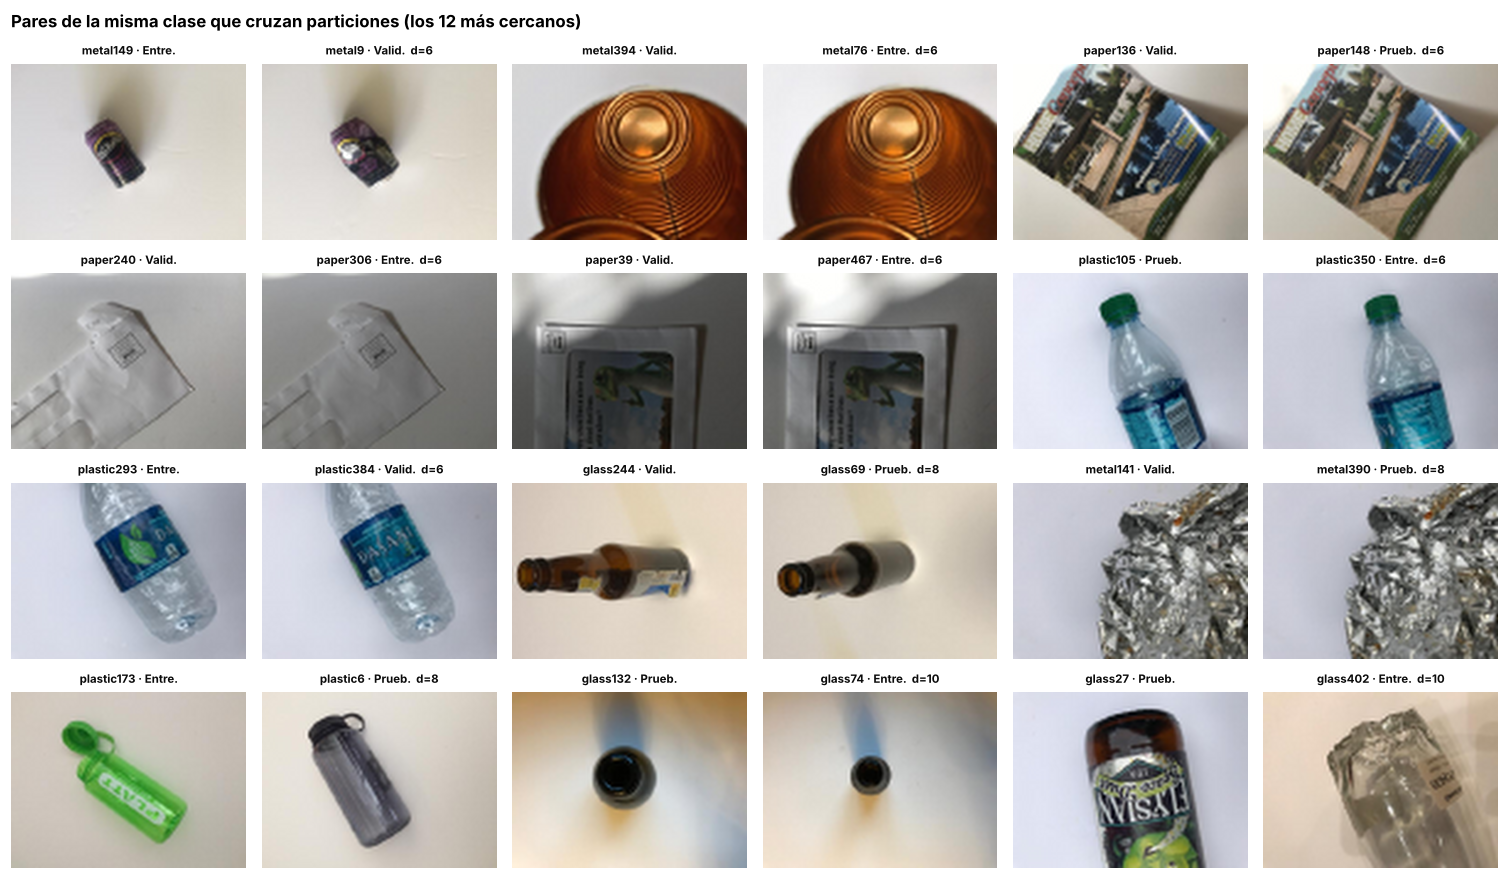

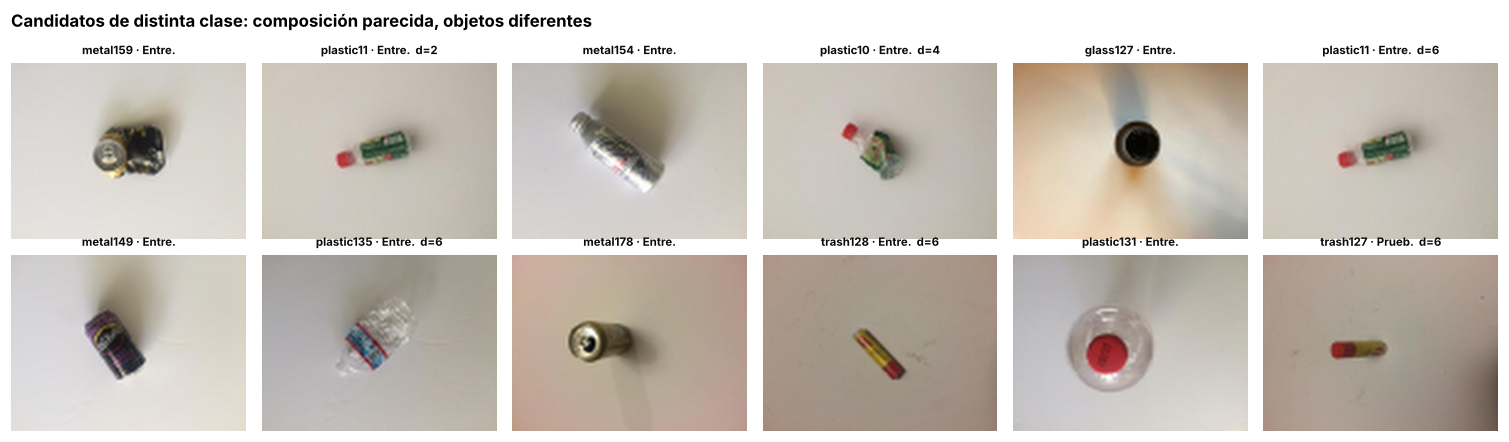

In [11]:
# @title Galerías de pares candidatos
def show_pairs(pair_index, title, ncols_pairs=3):
    """Galería de pares candidatos: archivo, partición de la fase 1 y distancia."""
    rows = int(np.ceil(len(pair_index) / ncols_pairs))
    fig, axes = plt.subplots(rows, 2 * ncols_pairs, figsize=(2.3 * 2 * ncols_pairs, 2.05 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for k, p in enumerate(pair_index):
        r, c = divmod(k, ncols_pairs)
        for side, idx in enumerate((iu[p], ju[p])):
            item = usable.iloc[idx]
            ax = axes[r, 2 * c + side]
            ax.imshow(THUMBS[item["ruta"]], interpolation="lanczos")
            label = f"{Path(item['ruta']).stem} · {SPLIT_ES[item['particion_fase1']][:5]}."
            if side == 1:
                label += f"  d={pair_dist[p]}"
            ax.set_title(label, fontsize=7.5, color=INK)
    fig.suptitle(title, fontsize=11, fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    plt.show()


cross_same = np.where(same_class & crosses & (pair_dist <= 10))[0]
cross_same = cross_same[np.argsort(pair_dist[cross_same], kind="stable")]
show_pairs(cross_same[:12], "Pares de la misma clase que cruzan particiones (los 12 más cercanos)")

cross_diff = np.where(~same_class & (pair_dist <= 8))[0]
cross_diff = cross_diff[np.argsort(pair_dist[cross_diff], kind="stable")]
show_pairs(cross_diff[:6], "Candidatos de distinta clase: composición parecida, objetos diferentes")

**Lectura de la revisión visual.** Los siete pares de la **misma clase** a distancia 6 son fotografías del **mismo objeto** tomadas dos veces con un leve desplazamiento (por ejemplo `plastic293`/`plastic384`, `paper39`/`paper467`, `metal394`/`metal76` o `paper136`/`paper148`) y hoy están en particiones distintas. A distancia 8 y 10 siguen apareciendo objetos repetidos (`glass244`/`glass69`, `metal141`/`metal390`, `glass132`/`glass74`), mezclados con falsos positivos (`plastic173`/`plastic6`, `glass27`/`glass402`). En cambio, los candidatos de **distinta clase** son objetos diferentes con una composición parecida: un objeto pequeño y centrado sobre fondo claro produce huellas similares. Por eso la similitud perceptual no se usa para corregir etiquetas.

**Decisión.** Se amplía el agrupamiento de la fase 1 con una regla adicional: **misma clase y distancia ≤ 10**. Unir dos imágenes que en realidad son distintas solo obliga a que compartan partición, un costo pequeño; dejar separadas dos tomas del mismo objeto infla la validación y la prueba. Con 12, el número de pares se triplica y los grupos se encadenan (la tabla muestra el salto del grupo más grande y de las reasignaciones), así que 10 es el punto de equilibrio. Para cada grupo que cruce particiones, **todas sus imágenes pasan a entrenamiento**: validación y prueba solo pierden imágenes, nunca reciben nuevas, y la prueba sigue siendo un subconjunto de la definida en la fase 1. Como aún no se ha entrenado ningún modelo, la corrección no introduce sesgo de selección.

In [12]:
NEAR_DUP_THRESHOLD = 10
edge_mask = (pair_dist <= NEAR_DUP_THRESHOLD) & same_class
paths = usable["ruta"].to_numpy()
edges_new = list(zip(paths[iu[edge_mask]], paths[ju[edge_mask]]))
usable["grupo"] = component_labels(paths.tolist(), edges_f1 + edges_new)

crossing_groups = usable.groupby("grupo")["particion_fase1"].nunique()
crossing_groups = set(crossing_groups[crossing_groups > 1].index)
usable["particion"] = np.where(usable["grupo"].isin(crossing_groups), "entrenamiento", usable["particion_fase1"])
moved = usable.loc[usable["particion"] != usable["particion_fase1"]]

group_sizes = usable["grupo"].value_counts()
print(f"Pares de la misma clase con distancia ≤ {NEAR_DUP_THRESHOLD}: {int(edge_mask.sum())}")
print(f"Grupos: {usable['grupo'].nunique()} | con más de una imagen: {int((group_sizes > 1).sum())} "
      f"| tamaño máximo: {group_sizes.max()}")
print(f"Grupos que cruzaban particiones: {len(crossing_groups)} | imágenes reasignadas a entrenamiento: {len(moved)}")
display(pd.crosstab(moved["clase"].map(LABEL_ES), moved["particion_fase1"].map(SPLIT_ES), margins=True,
                    margins_name="Total").rename_axis(index="clase", columns="venían de"))

split_table = pd.crosstab(usable["clase"], usable["particion"]).reindex(index=CLASSES, columns=SPLITS)
comparison = pd.concat({"Fase 1": phase1_table, "Fase 2": split_table}, axis=1)
display(comparison.rename(index=LABEL_ES).rename(columns=SPLIT_ES, level=1))
display(usable["particion"].value_counts().reindex(SPLITS).to_frame("imágenes")
        .assign(porcentaje=lambda f: (100 * f["imágenes"] / len(usable)).round(2)).rename(index=SPLIT_ES))

Pares de la misma clase con distancia ≤ 10: 79
Grupos: 2441 | con más de una imagen: 68 | tamaño máximo: 6
Grupos que cruzaban particiones: 21 | imágenes reasignadas a entrenamiento: 26


venían de,Prueba,Validación,Total
clase,,,
Metal,2,6,8
Papel,1,3,4
Plástico,4,4,8
Vidrio,4,2,6
Total,11,15,26


Fase 1                          Fase 2             \
particion_fase1 Entrenamiento Validación Prueba Entrenamiento Validación   
clase                                                                      
Cartón                    286         61     56           286         61   
Vidrio                    346         76     76           352         74   
Metal                     285         62     62           293         56   
Papel                     419         86     89           423         83   
Plástico                  338         71     71           346         67   
Residual                   98         19     20            98         19   

                        
particion_fase1 Prueba  
clase                   
Cartón              56  
Vidrio              72  
Metal               60  
Papel               88  
Plástico            67  
Residual            20

,imágenes,porcentaje
particion,,
Entrenamiento,1798,71.32
Validación,360,14.28
Prueba,363,14.40


### 1.3. Tipos de variables
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continua o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

#### 1.3.1 Diccionario de variables

| Variable | Tipo | Papel en el proyecto |
|---|---|---|
| `clase` | **Categórica nominal**, 6 niveles | **Variable objetivo** (clasificación multiclase, una etiqueta por imagen) |
| Píxeles RGB (512 × 384 × 3, 0–255) | Numérica discreta de alta dimensión | **Única entrada del modelo**, tras el preprocesamiento de la sección 2 |
| `ruta`, `bytes`, `ancho`, `alto`, `formato`, `modo` | Identificador y metadatos técnicos | Control de calidad; no predictores (constantes o sin significado físico) |
| `sha256`, `pixel_sha256`, `phash`, `grupo` | Huellas e identificadores de grupo | Control de duplicados y de particiones; nunca predictores |
| Descriptores visuales (tabla siguiente) | Numéricas continuas derivadas | Análisis descriptivo, detección de atípicos y de posibles atajos; no se incorporan al modelo |

TrashNet **no incluye variables adicionales** (no hay fecha, lugar, dispositivo, sesión ni identificador del objeto físico). Para describir el contenido visual se derivaron descriptores interpretables. **No se incorporan como entradas** de las redes: una CNN aprende sus propias representaciones a partir de los píxeles, y agregar estadísticos globales facilitaría que el modelo se apoye en el fondo o la iluminación en lugar del material. Sí se usan para describir las clases, decidir aumentos, detectar atípicos y construir una línea base de referencia.

| Descriptor | Definición | Qué revela |
|---|---|---|
| `brillo` | Media de la luminancia Y = 0,299R + 0,587G + 0,114B (0–255) | Exposición general |
| `contraste` | Desviación estándar de la luminancia | Diferencia entre objeto y fondo |
| `saturacion` | Media del canal S en HSV (%) | Intensidad del color |
| `colorido` | Métrica de Hasler y Süsstrunk [5] | Variedad y viveza cromática |
| `nitidez` | log10 de la varianza del laplaciano [6] | Desenfoque (valores bajos) |
| `entropia` | Entropía de Shannon del histograma de luminancia (bits) | Cantidad de información tonal |
| `sobreexpuesta` / `oscura` | % de píxeles con Y ≥ 250 / Y < 40 | Recortes de exposición |
| `borde_brillo`, `borde_calidez`, `borde_variacion` | Brillo, R − B y variación en la franja de 16 px del borde | Fondo y tono de la iluminación |
| `energia_lateral` | % de la energía de bordes (Sobel) en las franjas laterales de 64 px | Contenido que perdería un recorte central cuadrado |
| `media_R/G/B`, `borde_R/G/B` | Medias por canal en toda la imagen y en el borde | Color global y del fondo |

#### 1.3.2 Distribución de la variable objetivo

,valor
Razón clase mayor / clase menor (entrenamiento),"4,32 : 1"
Clase mayoritaria,"paper (23,5 %)"
Clase minoritaria,"trash (5,5 %)"
Proporción uniforme de referencia,"16,7 %"
Entropía normalizada (1 = balance perfecto),"0,962"
Imágenes de 'trash' en validación / prueba,19 / 20


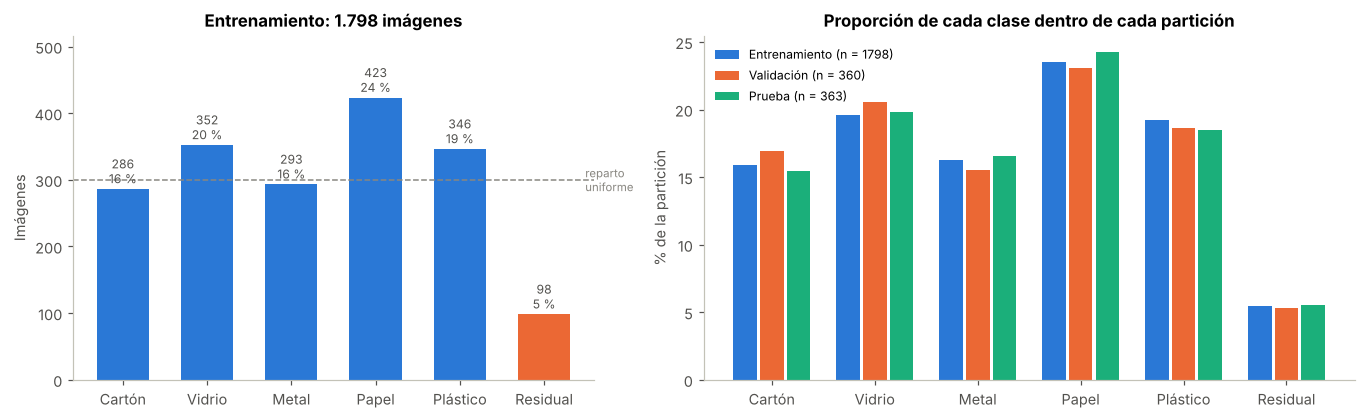

In [13]:
# @title 1.3.2 Distribución de la variable objetivo
train = usable.loc[usable["particion"].eq("entrenamiento")].copy()
val = usable.loc[usable["particion"].eq("validacion")].copy()
train_counts = split_table["entrenamiento"]
proportions = train_counts / train_counts.sum()
normalized_entropy = float(-(proportions * np.log(proportions)).sum() / np.log(len(CLASSES)))
imbalance = pd.Series({
    "Razón clase mayor / clase menor (entrenamiento)": f"{dec(train_counts.max() / train_counts.min())} : 1",
    "Clase mayoritaria": f"{train_counts.idxmax()} ({pct(proportions.max())})",
    "Clase minoritaria": f"{train_counts.idxmin()} ({pct(proportions.min())})",
    "Proporción uniforme de referencia": pct(1 / len(CLASSES)),
    "Entropía normalizada (1 = balance perfecto)": dec(normalized_entropy, 3),
    "Imágenes de 'trash' en validación / prueba": f"{split_table.loc['trash', 'validacion']} / {split_table.loc['trash', 'prueba']}",
}, name="valor").to_frame()
display(imbalance)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
bar_colors = ["#eb6834" if c == "trash" else "#2a78d6" for c in CLASSES]
bars = ax.bar([LABEL_ES[c] for c in CLASSES], train_counts.values, color=bar_colors, width=0.62)
ax.bar_label(bars, labels=[f"{n}\n{pct(p, 0)}" for n, p in zip(train_counts, proportions)],
             padding=2, fontsize=8, color=INK_2)
ax.axhline(train_counts.sum() / len(CLASSES), color=MUTED, ls="--", lw=1)
ax.text(5.45, train_counts.sum() / len(CLASSES), " reparto\n uniforme", va="center", fontsize=7.5, color=MUTED)
ax.set(title=f"Entrenamiento: {miles(train_counts.sum())} imágenes", ylabel="Imágenes")
ax.set_ylim(0, train_counts.max() * 1.22)

ax = axes[1]
width = 0.26
share = split_table / split_table.sum()
for k, split in enumerate(SPLITS):
    ax.bar(np.arange(len(CLASSES)) + (k - 1) * width, 100 * share[split], width=width - 0.03,
           color=SPLIT_COLORS[split], label=f"{SPLIT_ES[split]} (n = {split_table[split].sum()})")
ax.set_xticks(np.arange(len(CLASSES)), [LABEL_ES[c] for c in CLASSES])
ax.set(title="Proporción de cada clase dentro de cada partición", ylabel="% de la partición")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

In [14]:
# @title Respuesta 1.3 (objetivo y desbalance)
display(Markdown(
    "**Respuesta 1.3 (objetivo y desbalance).** Sí hay variable objetivo: `clase`, **categórica nominal** "
    "con seis niveles, por lo que el problema es de clasificación multiclase (no de regresión). Hay un "
    f"**desbalance moderado**: en entrenamiento `paper` reúne {pct(proportions['paper'])} y `trash` solo "
    f"{pct(proportions['trash'])}, una razón de {dec(train_counts.max() / train_counts.min())}:1. La entropía normalizada "
    f"({dec(normalized_entropy, 3)}) muestra que las cinco clases de materiales están relativamente equilibradas y que el "
    "problema se concentra en `trash`. Las proporciones son casi iguales en las tres particiones, de modo que la "
    "estratificación se conservó tras la corrección de casi duplicados. **Consecuencias:** la accuracy por sí sola sería "
    f"engañosa (predecir siempre `paper` acierta ≈ {pct(proportions.max(), 0)}); se usarán F1 macro y recall por clase, y se "
    "calcularán pesos por clase con entrenamiento (sección 2.7). Con "
    f"{split_table.loc['trash', 'validacion']} imágenes de `trash` en validación, cada acierto o error en esa clase mueve "
    f"su recall ≈ {dec(100 / split_table.loc['trash', 'validacion'], 1)} puntos: sus métricas deben leerse con cautela."
))

**Respuesta 1.3 (objetivo y desbalance).** Sí hay variable objetivo: `clase`, **categórica nominal** con seis niveles, por lo que el problema es de clasificación multiclase (no de regresión). Hay un **desbalance moderado**: en entrenamiento `paper` reúne 23,5 % y `trash` solo 5,5 %, una razón de 4,32:1. La entropía normalizada (0,962) muestra que las cinco clases de materiales están relativamente equilibradas y que el problema se concentra en `trash`. Las proporciones son casi iguales en las tres particiones, de modo que la estratificación se conservó tras la corrección de casi duplicados. **Consecuencias:** la accuracy por sí sola sería engañosa (predecir siempre `paper` acierta ≈ 24 %); se usarán F1 macro y recall por clase, y se calcularán pesos por clase con entrenamiento (sección 2.7). Con 19 imágenes de `trash` en validación, cada acierto o error en esa clase mueve su recall ≈ 5,3 puntos: sus métricas deben leerse con cautela.

#### 1.3.3 Muestra visual por clase (entrenamiento)

Antes de resumir con números conviene mirar las imágenes: la muestra es aleatoria y reproducible (semilla 42).

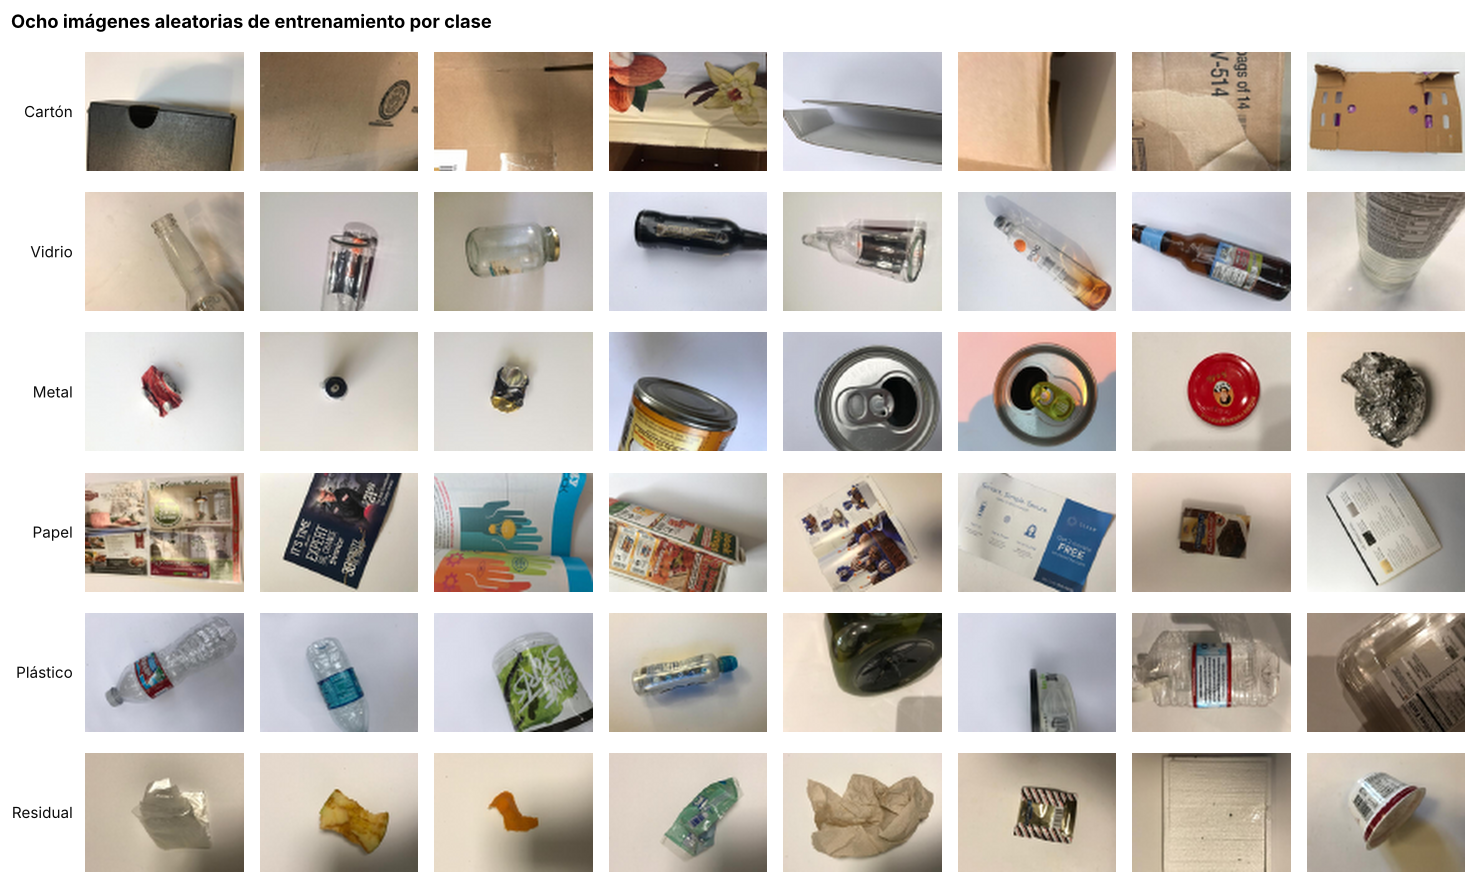

In [15]:
# @title 1.3.3 Muestra visual por clase
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(13.5, 8.2))
for r, label in enumerate(CLASSES):
    sample = train.loc[train["clase"].eq(label)].sample(8, random_state=SEED)
    for c, (_, item) in enumerate(sample.iterrows()):
        ax = axes[r, c]
        ax.imshow(THUMBS[item["ruta"]], interpolation="lanczos")
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if c == 0:
            ax.set_ylabel(LABEL_ES[label], fontsize=10, color=INK, rotation=0, ha="right", va="center", labelpad=8)
fig.suptitle("Ocho imágenes aleatorias de entrenamiento por clase", fontsize=12, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Lo que se observa.** Cada foto muestra un objeto (o un primer plano) sobre una cartulina clara. Hay tres rasgos que el análisis cuantitativo debe confirmar: **(1)** muchas fotos de cartón y papel son primeros planos que llenan el encuadre, mientras botellas y latas aparecen enteras y centradas; **(2)** el tono del fondo cambia entre sesiones de captura, con fondos más cálidos (beige) en `trash` y más fríos (azulados) en `plastic`; **(3)** el plástico transparente y el vidrio claro tienen poco contraste con el fondo.

#### 1.3.4 Estadística descriptiva de los descriptores (entrenamiento)

In [16]:
# @title 1.3.4 Estadística descriptiva por clase
DESCRIPTORS = {
    "brillo": "Brillo", "contraste": "Contraste", "saturacion": "Saturación (%)", "colorido": "Colorido",
    "nitidez": "Nitidez (log10)", "entropia": "Entropía (bits)", "sobreexpuesta": "Sobreexpuesta (%)",
    "oscura": "Oscura (%)", "borde_brillo": "Brillo del borde", "borde_calidez": "Calidez del borde (R−B)",
    "borde_variacion": "Variación del borde", "energia_lateral": "Estructura lateral (%)", "kb": "Archivo (KB)",
}
ANALYSIS_COLS = list(DESCRIPTORS) + ["media_R", "media_G", "media_B"]
ANALYSIS_NAMES = DESCRIPTORS | {"media_R": "Media R (rojo)", "media_G": "Media G (verde)", "media_B": "Media B (azul)"}

summary_stats = train[list(DESCRIPTORS)].describe().T
summary_stats["asimetría"] = train[list(DESCRIPTORS)].skew()
display(summary_stats.rename(index=DESCRIPTORS).round(2))

by_class = train.groupby("clase")[list(DESCRIPTORS)].median().reindex(CLASSES).T
by_class["rango entre clases"] = by_class.max(axis=1) - by_class.min(axis=1)
display(by_class.rename(index=DESCRIPTORS, columns=LABEL_ES).round(2)
        .style.format(precision=2).background_gradient(cmap=SEQUENTIAL, axis=1, subset=[LABEL_ES[c] for c in CLASSES])
        .set_caption("Mediana de cada descriptor por clase (entrenamiento); el color compara clases dentro de cada fila"))

,count,mean,std,min,25%,50%,75%,max,asimetría
Brillo,1798.0,164.69,20.29,81.23,153.56,168.64,177.67,222.45,-0.77
Contraste,1798.0,45.97,15.54,7.49,34.42,44.95,57.09,98.55,0.27
Saturación (%),1798.0,17.61,11.14,0.80,9.21,15.35,22.78,67.60,1.19
Colorido,1798.0,25.42,16.03,2.68,13.31,21.90,33.13,128.47,1.49
Nitidez (log10),1798.0,2.59,0.51,0.61,2.26,2.61,2.94,3.92,-0.37
Entropía (bits),1798.0,6.75,0.54,4.22,6.49,6.80,7.10,7.77,-0.94
Sobreexpuesta (%),1798.0,0.52,3.60,0.00,0.00,0.00,0.07,59.31,11.48
Oscura (%),1798.0,2.68,5.05,0.00,0.00,0.57,3.03,52.43,3.61
Brillo del borde,1798.0,179.25,23.05,69.18,167.16,182.79,193.54,253.08,-0.59
Calidez del borde (R−B),1798.0,15.14,23.12,-53.28,-3.30,14.92,29.76,108.04,0.49


clase,Cartón,Vidrio,Metal,Papel,Plástico,Residual,rango entre clases
Brillo,153.28,172.61,161.15,170.55,172.15,169.79,19.33
Contraste,44.23,45.53,54.32,49.00,36.57,45.18,17.75
Saturación (%),31.60,14.01,16.67,13.23,9.59,18.64,22.01
Colorido,31.93,18.27,21.07,22.02,18.06,23.32,13.87
Nitidez (log10),2.59,2.42,2.81,2.89,2.51,2.58,0.46
Entropía (bits),6.98,6.70,6.89,6.99,6.69,6.60,0.39
Sobreexpuesta (%),0.00,0.00,0.03,0.00,0.00,0.01,0.03
Oscura (%),0.47,0.90,2.81,0.24,0.12,0.21,2.69
Brillo del borde,156.24,188.77,181.23,184.66,183.37,180.37,32.53
Calidez del borde (R−B),44.70,17.75,12.41,11.78,-8.20,29.35,52.90


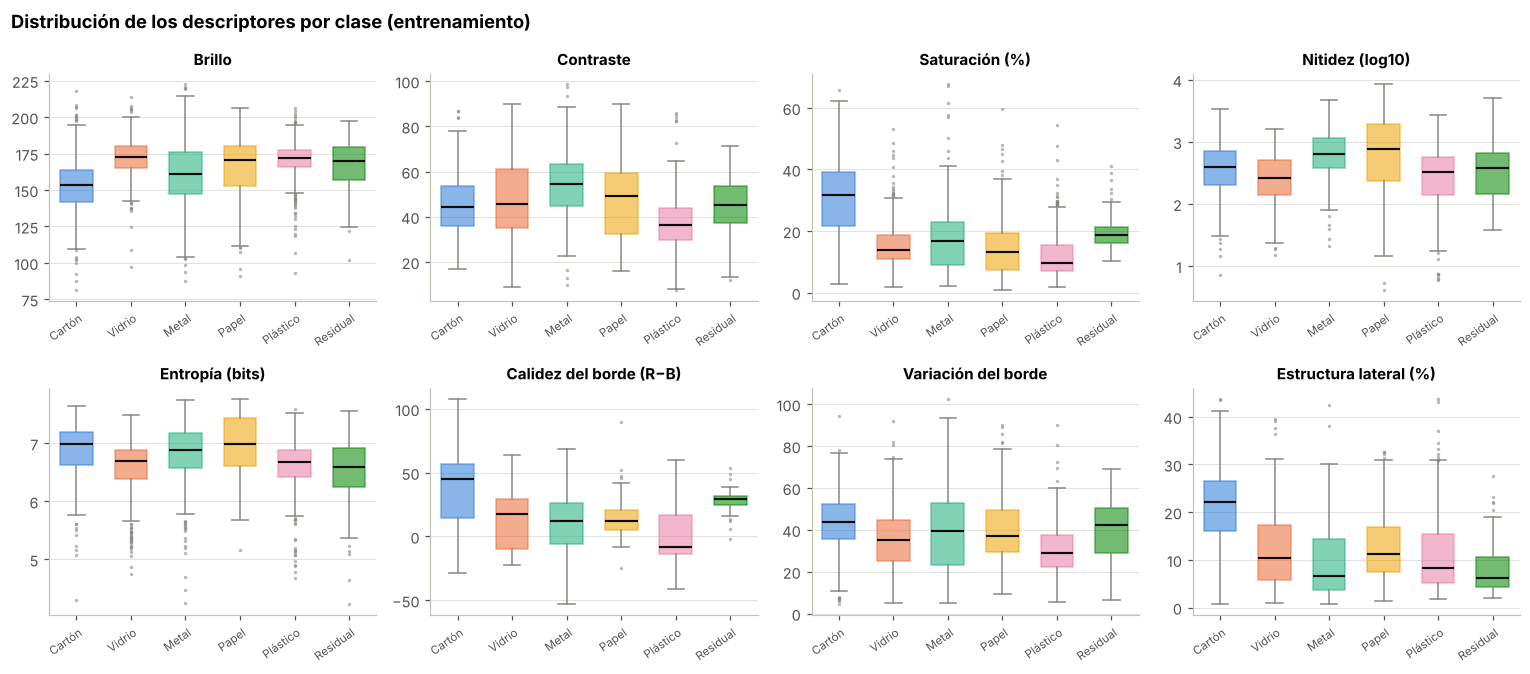

In [17]:
# @title Diagramas de caja por clase
BOX_COLS = ["brillo", "contraste", "saturacion", "nitidez", "entropia", "borde_calidez", "borde_variacion", "energia_lateral"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.2))
for ax, col in zip(axes.ravel(), BOX_COLS):
    data = [train.loc[train["clase"].eq(c), col] for c in CLASSES]
    parts = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=True,
                       medianprops={"color": INK, "lw": 1.4},
                       flierprops={"marker": "o", "markersize": 2.2, "markerfacecolor": MUTED,
                                   "markeredgecolor": "none", "alpha": 0.6},
                       whiskerprops={"color": MUTED}, capprops={"color": MUTED})
    for patch, c in zip(parts["boxes"], CLASSES):
        patch.set(facecolor=CLASS_COLORS[c], alpha=0.55, edgecolor=CLASS_COLORS[c])
    ax.set_xticks(range(1, len(CLASSES) + 1), [LABEL_ES[c] for c in CLASSES], fontsize=7.5, rotation=35, ha="right",
                  rotation_mode="anchor")
    ax.set_title(DESCRIPTORS[col], fontsize=10)
    ax.grid(axis="y", color="#e1e0d9", lw=0.6)
    ax.set_axisbelow(True)
fig.suptitle("Distribución de los descriptores por clase (entrenamiento)", fontsize=12, fontweight="bold",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()

#### 1.3.5 Imagen promedio y ubicación de la estructura por clase

La **imagen promedio** revela regularidades de encuadre y de fondo compartidas por la clase. El **mapa de estructura** promedia la magnitud de los bordes (Sobel) y muestra dónde suele estar el contenido; las líneas punteadas marcan lo que conservaría un recorte central cuadrado (384 × 384 px). Cada mapa se normaliza por su propia media para comparar la distribución espacial, no la cantidad de bordes.

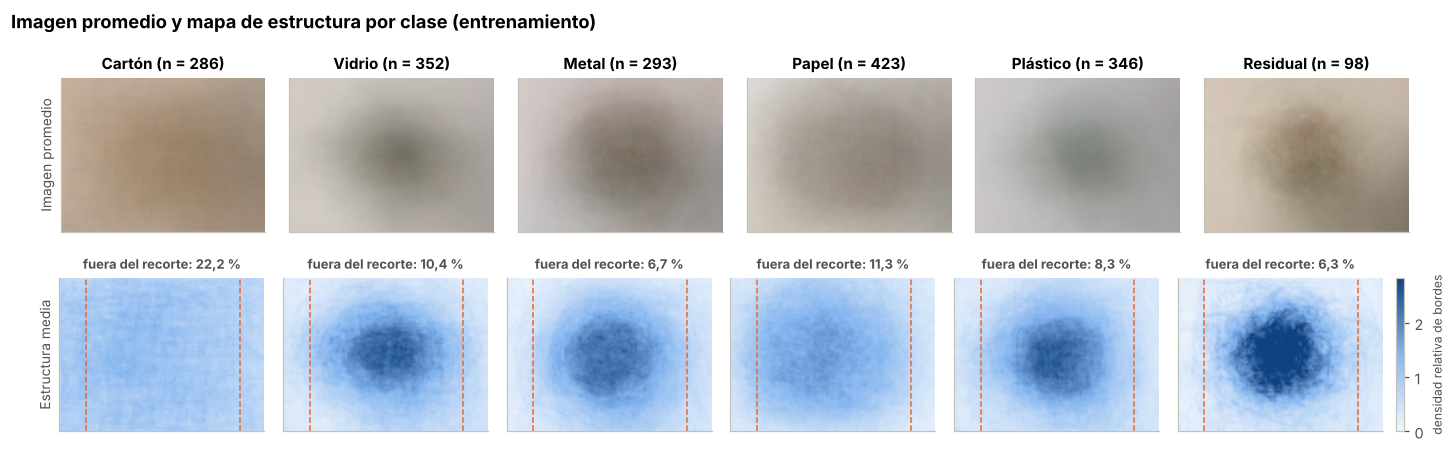

In [18]:
# @title 1.3.5 Imagen promedio y mapa de estructura por clase
crop_left = 64 / 512 * THUMB_WH[0]
crop_right = (512 - 64) / 512 * THUMB_WH[0]
fig, axes = plt.subplots(2, len(CLASSES), figsize=(14, 4.4))
energy_maps = {}
for k, label in enumerate(CLASSES):
    routes = train.loc[train["clase"].eq(label), "ruta"]
    mean_image = np.mean([THUMBS[r] for r in routes], axis=0)
    energy_map = np.mean([ENERGY[r] for r in routes], axis=0)
    energy_maps[label] = energy_map / energy_map.mean()
    axes[0, k].imshow(mean_image.astype(np.uint8), interpolation="lanczos")
    axes[0, k].set_title(f"{LABEL_ES[label]} (n = {len(routes)})", fontsize=10)
fig.subplots_adjust(left=0.04, right=0.92, top=0.84, wspace=0.08, hspace=0.3)
vmax = np.percentile(np.stack(list(energy_maps.values())), 99)
for k, label in enumerate(CLASSES):
    im = axes[1, k].imshow(energy_maps[label], cmap=SEQUENTIAL, vmin=0, vmax=vmax, interpolation="bilinear")
    for x in (crop_left, crop_right):
        axes[1, k].axvline(x, color="#eb6834", ls="--", lw=1)
    lateral_share = train.loc[train["clase"].eq(label), "energia_lateral"].median()
    axes[1, k].set_title(f"fuera del recorte: {dec(lateral_share, 1)} %", fontsize=8.5, color=INK_2)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("Imagen promedio", fontsize=9)
axes[1, 0].set_ylabel("Estructura media", fontsize=9)
cbar = fig.colorbar(im, ax=axes[1, :].tolist(), fraction=0.012, pad=0.01)
cbar.set_label("densidad relativa de bordes", fontsize=8)
fig.suptitle("Imagen promedio y mapa de estructura por clase (entrenamiento)", fontsize=12,
             fontweight="bold", x=0.01, ha="left")
plt.show()

#### 1.3.6 El color del fondo por clase

Cada fila muestra el color medio de la franja del borde (16 px) de 60 imágenes de entrenamiento elegidas al azar, ordenadas de más fría a más cálida. Si el fondo fuera independiente de la clase, las seis filas se verían iguales.

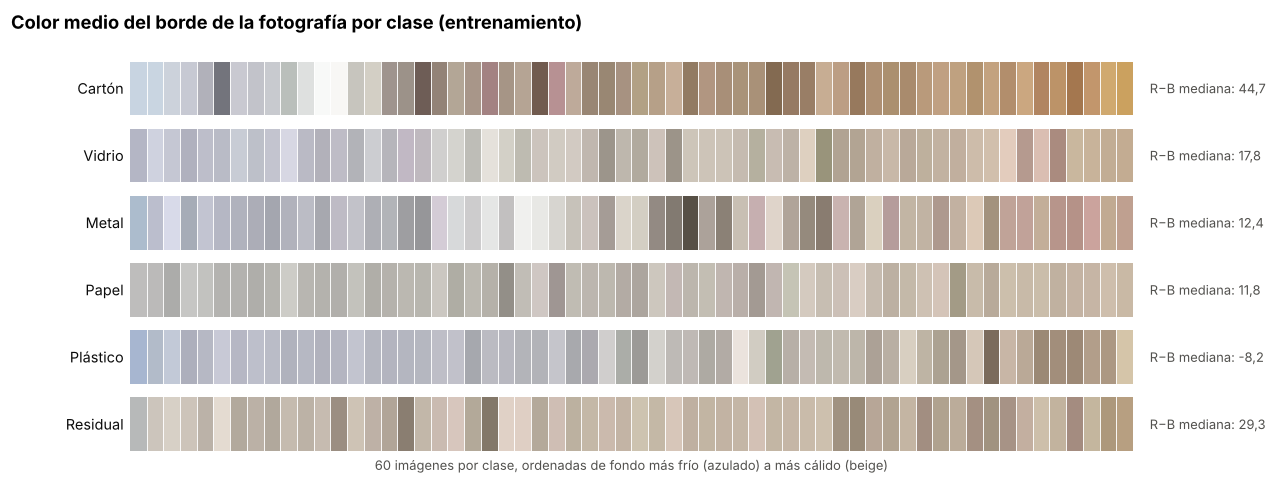

In [19]:
# @title 1.3.6 Color del fondo por clase
fig, axes = plt.subplots(len(CLASSES), 1, figsize=(12, 4.6), sharex=True)
for ax, label in zip(axes, CLASSES):
    sample = train.loc[train["clase"].eq(label)].sample(60, random_state=SEED).sort_values("borde_calidez")
    swatch = sample[["borde_R", "borde_G", "borde_B"]].to_numpy()[None, :, :] / 255
    ax.imshow(swatch, aspect="auto", extent=(0, 60, 0, 1))
    for x in range(1, 60):
        ax.axvline(x, color="white", lw=0.6)
    ax.set_yticks([])
    ax.set_ylabel(LABEL_ES[label], rotation=0, ha="right", va="center", fontsize=9.5, color=INK)
    median = train.loc[train["clase"].eq(label), "borde_calidez"].median()
    ax.text(61, 0.5, f"R−B mediana: {dec(median, 1)}", va="center", fontsize=8.5, color=INK_2)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[-1].set_xticks([])
axes[-1].set_xlabel("60 imágenes por clase, ordenadas de fondo más frío (azulado) a más cálido (beige)", fontsize=8.5)
fig.suptitle("Color medio del borde de la fotografía por clase (entrenamiento)", fontsize=12,
             fontweight="bold", x=0.01, ha="left")
fig.subplots_adjust(left=0.1, right=0.86, hspace=0.25)
plt.show()

In [20]:
# @title Respuesta 1.3 (variables adicionales y lectura descriptiva)
med = train.groupby("clase")[list(DESCRIPTORS)].median()
display(Markdown(
    "**Respuesta 1.3 (variables adicionales y lectura descriptiva).** Los descriptores confirman y cuantifican lo "
    "observado:\n\n"
    f"- **Color:** el cartón es la clase más saturada (mediana {dec(med.loc['cardboard', 'saturacion'], 1)} %) y el "
    f"plástico la menos saturada ({dec(med.loc['plastic', 'saturacion'], 1)} %), coherente con envases transparentes. "
    "El color es una señal legítima del material, pero no suficiente: vidrio, metal y papel se solapan.\n"
    f"- **Contraste y reflejos:** el plástico tiene el menor contraste ({dec(med.loc['plastic', 'contraste'], 1)}) y el metal "
    f"el mayor ({dec(med.loc['metal', 'contraste'], 1)}), con más píxeles oscuros por reflejos "
    f"({dec(med.loc['metal', 'oscura'], 1)} % frente a {dec(med['oscura'].drop('metal').max(), 1)} % como máximo en las demás clases).\n"
    f"- **Fondo:** la calidez del borde va de {dec(med['borde_calidez'].min(), 1)} en "
    f"`{med['borde_calidez'].idxmin()}` a {dec(med.loc['trash', 'borde_calidez'], 1)} en `trash` "
    f"(el valor del cartón, {dec(med.loc['cardboard', 'borde_calidez'], 1)}, refleja sobre todo que el material llena el "
    "borde). Las fotos de cada clase se tomaron en sesiones con iluminación distinta, así que **el fondo está asociado a "
    "la etiqueta**: un modelo podría aprender ese atajo en lugar del material [9].\n"
    f"- **Encuadre:** en cartón la mediana de estructura que caería fuera de un recorte central es "
    f"{dec(med.loc['cardboard', 'energia_lateral'], 1)} %; en las demás clases está entre "
    f"{dec(med['energia_lateral'].drop('cardboard').min(), 1)} % y {dec(med['energia_lateral'].drop('cardboard').max(), 1)} %. "
    "Los mapas de estructura lo confirman: en vidrio, metal, plástico y residual el contenido se concentra en el centro, "
    "mientras que en cartón y papel se reparte hasta los bordes.\n"
    "- **Exposición:** `sobreexpuesta` y `oscura` son muy asimétricas (la mayoría de imágenes tiene 0 %); requieren "
    "umbrales de dominio y no reglas basadas en cuartiles (sección 1.5).\n\n"
    "Ningún descriptor se incorpora al modelo; su papel es orientar el preprocesamiento (relleno en lugar de recorte, "
    "aumentos de color e iluminación) y el análisis de errores."
))

**Respuesta 1.3 (variables adicionales y lectura descriptiva).** Los descriptores confirman y cuantifican lo observado:

- **Color:** el cartón es la clase más saturada (mediana 31,6 %) y el plástico la menos saturada (9,6 %), coherente con envases transparentes. El color es una señal legítima del material, pero no suficiente: vidrio, metal y papel se solapan.
- **Contraste y reflejos:** el plástico tiene el menor contraste (36,6) y el metal el mayor (54,3), con más píxeles oscuros por reflejos (2,8 % frente a 0,9 % como máximo en las demás clases).
- **Fondo:** la calidez del borde va de -8,2 en `plastic` a 29,3 en `trash` (el valor del cartón, 44,7, refleja sobre todo que el material llena el borde). Las fotos de cada clase se tomaron en sesiones con iluminación distinta, así que **el fondo está asociado a la etiqueta**: un modelo podría aprender ese atajo en lugar del material [9].
- **Encuadre:** en cartón la mediana de estructura que caería fuera de un recorte central es 22,2 %; en las demás clases está entre 6,3 % y 11,3 %. Los mapas de estructura lo confirman: en vidrio, metal, plástico y residual el contenido se concentra en el centro, mientras que en cartón y papel se reparte hasta los bordes.
- **Exposición:** `sobreexpuesta` y `oscura` son muy asimétricas (la mayoría de imágenes tiene 0 %); requieren umbrales de dominio y no reglas basadas en cuartiles (sección 1.5).

Ningún descriptor se incorpora al modelo; su papel es orientar el preprocesamiento (relleno en lugar de recorte, aumentos de color e iluminación) y el análisis de errores.

### 1.4. Relación entre variables
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

Se usa la **correlación de Spearman** porque varios descriptores son asimétricos y la relación esperada es monótona, no necesariamente lineal. Para la relación de cada descriptor con la clase (categórica) se usan el **tamaño del efecto de Kruskal-Wallis**, ε² = (H − k + 1)/(n − k) [7], y la **información mutua**. Como referencia orientativa para ε² se marcan los cortes habituales de η² (0,06 moderado; 0,14 grande).

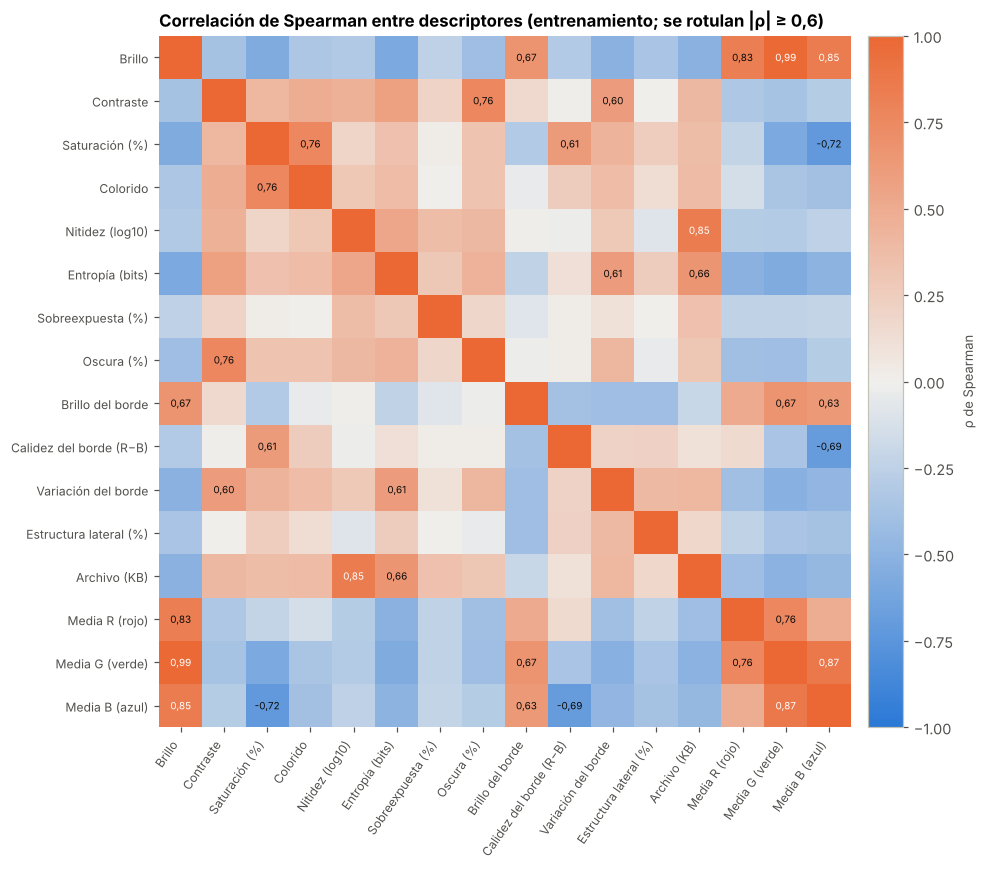

,,ρ
Brillo,Media G (verde),0.991
Media G (verde),Media B (azul),0.871
Brillo,Media B (azul),0.851
Nitidez (log10),Archivo (KB),0.850
Brillo,Media R (rojo),0.827


In [21]:
# @title 1.4 Correlaciones de Spearman entre descriptores
corr = train[ANALYSIS_COLS].corr(method="spearman")
names = [ANALYSIS_NAMES[c] for c in ANALYSIS_COLS]
fig, ax = plt.subplots(figsize=(9.6, 8))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(names)), names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        if i != j and abs(corr.iat[i, j]) >= 0.6:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=6.5,
                    color="white" if abs(corr.iat[i, j]) >= 0.85 else INK)
ax.spines[:].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("ρ de Spearman", fontsize=8.5)
ax.set_title("Correlación de Spearman entre descriptores (entrenamiento; se rotulan |ρ| ≥ 0,6)", loc="left")
fig.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, bool), k=1)).stack()
redundant = upper[upper.abs() >= 0.8].sort_values(key=np.abs, ascending=False)
display(redundant.rename("ρ").to_frame().rename(index=ANALYSIS_NAMES).round(3))

,H de Kruskal-Wallis,p,ε²,información mutua (nats)
descriptor,,,,
Saturación (%),426.9,4.7e-90,0.235,0.222
Media B (azul),367.7,2.7e-77,0.202,0.201
Calidez del borde (R−B),357.2,4.9e-75,0.197,0.367
Estructura lateral (%),328.4,7.7e-69,0.180,0.151
Archivo (KB),258.9,6.9e-54,0.142,0.143
Media G (verde),234.1,1.4e-48,0.128,0.142
Nitidez (log10),219.2,2.2e-45,0.120,0.146
Contraste,201.6,1.3e-41,0.110,0.109
Brillo,200.3,2.4e-41,0.109,0.145


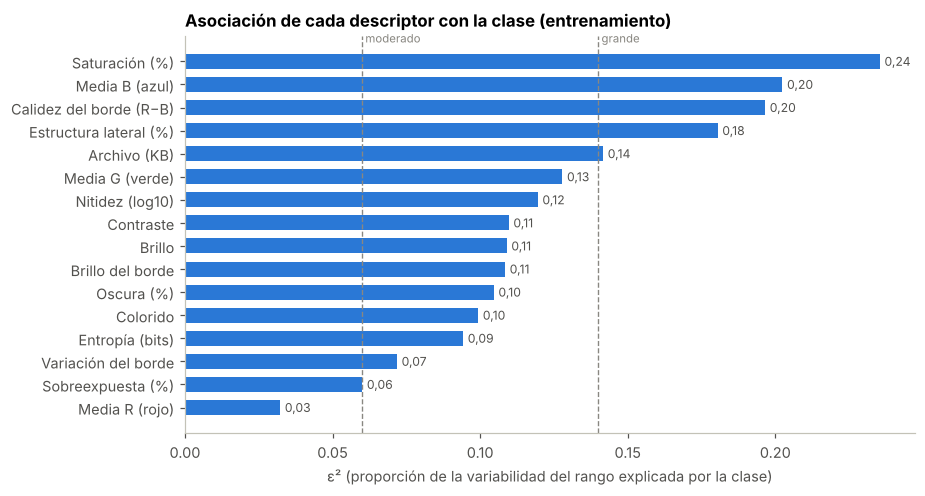

In [22]:
# @title Asociación de cada descriptor con la clase
y_train = train["clase"].to_numpy()
association = []
mutual_info = mutual_info_classif(train[ANALYSIS_COLS], y_train, random_state=SEED)
for col, mi in zip(ANALYSIS_COLS, mutual_info):
    h, p = stats.kruskal(*[train.loc[train["clase"].eq(c), col] for c in CLASSES])
    n, k = len(train), len(CLASSES)
    association.append({"descriptor": ANALYSIS_NAMES[col],
                        "H de Kruskal-Wallis": h, "p": p, "ε²": (h - k + 1) / (n - k),
                        "información mutua (nats)": mi})
association = pd.DataFrame(association).set_index("descriptor").sort_values("ε²", ascending=False)
display(association.style.format({"H de Kruskal-Wallis": "{:.1f}", "p": "{:.1e}", "ε²": "{:.3f}",
                                  "información mutua (nats)": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ordered = association["ε²"].sort_values()
bars = ax.barh(ordered.index, ordered.values, color="#2a78d6", height=0.65)
ax.bar_label(bars, labels=[f"{v:.2f}".replace(".", ",") for v in ordered.values], padding=3, fontsize=8, color=INK_2)
for threshold, text in [(0.06, "moderado"), (0.14, "grande")]:
    ax.axvline(threshold, color=MUTED, ls="--", lw=0.9)
    ax.text(threshold, len(ordered) - 0.3, f" {text}", fontsize=7.5, color=MUTED, va="bottom")
ax.set(xlabel="ε² (proporción de la variabilidad del rango explicada por la clase)")
ax.set_title("Asociación de cada descriptor con la clase (entrenamiento)", loc="left")
fig.tight_layout()
plt.show()

In [23]:
# @title Respuesta 1.4
top = association.index[:4].tolist()
bg_eps = association.loc["Calidez del borde (R−B)", "ε²"]
moderate = upper[(upper.abs() >= 0.7) & (upper.abs() < 0.8)].sort_values(key=np.abs, ascending=False)
redundant_text = "; ".join(f"{ANALYSIS_NAMES[a]} – {ANALYSIS_NAMES[b]} (ρ = {dec(v, 2)})" for (a, b), v in redundant.items())
moderate_text = "; ".join(f"{ANALYSIS_NAMES[a]} – {ANALYSIS_NAMES[b]} ({dec(v, 2)})" for (a, b), v in moderate.items())
all_significant = bool(association["p"].max() < 0.001)
display(Markdown(
    "**Respuesta 1.4.** **Relación con la clase:** "
    + ("todos los descriptores difieren entre clases (p < 0,001 en Kruskal-Wallis), " if all_significant
       else "la mayoría de descriptores difiere entre clases, ")
    + f"pero con fuerza muy distinta. Los más asociados son {', '.join(top)}. Que la calidez del "
    f"borde (fondo) tenga un ε² de {dec(bg_eps, 3)} confirma que **la iluminación de la sesión de captura está "
    "ligada a la etiqueta**; la sección 3 cuantifica cuánto se puede predecir solo con el fondo.\n\n"
    f"**Redundancia:** {len(redundant)} pares tienen |ρ| ≥ 0,8: {redundant_text}. Es decir, las medias por canal "
    "repiten la información del brillo, y la nitidez está ligada al tamaño del archivo (el detalle fino encarece la "
    f"compresión JPEG). Con |ρ| entre 0,7 y 0,8 aparecen además: {moderate_text}. Para el "
    "modelo esto no implica eliminar nada, porque los descriptores no son entradas; sí implica que la línea base de "
    "descriptores (sección 3) usa regularización y que, al describir resultados, basta un representante por familia: "
    "**brillo**, **contraste**, **saturación/colorido**, **nitidez**, **fondo** y **encuadre**. En los píxeles hay una "
    "redundancia análoga: los tres canales RGB están muy correlacionados, algo que las convoluciones manejan sin "
    "selección manual."
))

**Respuesta 1.4.** **Relación con la clase:** todos los descriptores difieren entre clases (p < 0,001 en Kruskal-Wallis), pero con fuerza muy distinta. Los más asociados son Saturación (%), Media B (azul), Calidez del borde (R−B), Estructura lateral (%). Que la calidez del borde (fondo) tenga un ε² de 0,197 confirma que **la iluminación de la sesión de captura está ligada a la etiqueta**; la sección 3 cuantifica cuánto se puede predecir solo con el fondo.

**Redundancia:** 5 pares tienen |ρ| ≥ 0,8: Brillo – Media G (verde) (ρ = 0,99); Media G (verde) – Media B (azul) (ρ = 0,87); Brillo – Media B (azul) (ρ = 0,85); Nitidez (log10) – Archivo (KB) (ρ = 0,85); Brillo – Media R (rojo) (ρ = 0,83). Es decir, las medias por canal repiten la información del brillo, y la nitidez está ligada al tamaño del archivo (el detalle fino encarece la compresión JPEG). Con |ρ| entre 0,7 y 0,8 aparecen además: Media R (rojo) – Media G (verde) (0,76); Saturación (%) – Colorido (0,76); Contraste – Oscura (%) (0,76); Saturación (%) – Media B (azul) (-0,72). Para el modelo esto no implica eliminar nada, porque los descriptores no son entradas; sí implica que la línea base de descriptores (sección 3) usa regularización y que, al describir resultados, basta un representante por familia: **brillo**, **contraste**, **saturación/colorido**, **nitidez**, **fondo** y **encuadre**. En los píxeles hay una redundancia análoga: los tres canales RGB están muy correlacionados, algo que las convoluciones manejan sin selección manual.

### 1.5. Valores atípicos
---

En imágenes, un atípico no es un número fuera de rango sino una fotografía con **exposición, nitidez o contenido extremos**. Se evaluaron cinco reglas con umbrales fijados **solo con entrenamiento**; se conservan las cuatro que identifican casos (el contraste no presenta atípicos bajos, como muestra la salida). Para descriptores aproximadamente simétricos se usa la regla de Tukey (Q1 − 1,5·RIC). Para `sobreexpuesta` y `oscura`, cuya mediana es casi 0 %, una regla de cuartiles marcaría como atípicas imágenes normales, así que se usan umbrales de dominio.

In [24]:
# @title 1.5 Reglas de detección de atípicos
def tukey_low(col):
    q1, q3 = train[col].quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1)


OUTLIER_RULES = {
    "sobreexpuesta": ("> 10 % de píxeles con Y ≥ 250", lambda f: f["sobreexpuesta"] > 10),
    "oscura": ("> 25 % de píxeles con Y < 40", lambda f: f["oscura"] > 25),
    "borrosa": (f"nitidez < {dec(tukey_low('nitidez'))}", lambda f, t=tukey_low("nitidez"): f["nitidez"] < t),
    "poca_informacion": (f"entropía < {dec(tukey_low('entropia'))} bits", lambda f, t=tukey_low("entropia"): f["entropia"] < t),
}
for name, (_, rule) in OUTLIER_RULES.items():
    usable[f"atipico_{name}"] = rule(usable)
flag_cols = [f"atipico_{name}" for name in OUTLIER_RULES]
usable["atipico"] = usable[flag_cols].any(axis=1)
train = usable.loc[usable["particion"].eq("entrenamiento")].copy()

q1, q3 = train["sobreexpuesta"].quantile([0.25, 0.75])
iqr_would_flag = int((train["sobreexpuesta"] > q3 + 1.5 * (q3 - q1)).sum())
outlier_table = pd.DataFrame({
    "regla": [desc for desc, _ in OUTLIER_RULES.values()],
    "imágenes (entrenamiento)": [int(train[c].sum()) for c in flag_cols],
    "% de entrenamiento": [round(100 * train[c].mean(), 2) for c in flag_cols],
}, index=list(OUTLIER_RULES))
display(outlier_table)
by_class_flags = train.groupby("clase")[flag_cols].sum().reindex(CLASSES)
by_class_flags["alguna regla"] = train.groupby("clase")["atipico"].sum().reindex(CLASSES)
by_class_flags["% de la clase"] = (100 * by_class_flags["alguna regla"] / train_counts).round(1)
display(by_class_flags.rename(index=LABEL_ES, columns=lambda c: c.replace("atipico_", "")))
print(f"El contraste no tiene atípicos bajos: el límite de Tukey ({dec(tukey_low('contraste'))}) queda por debajo "
      f"del mínimo observado ({dec(train['contraste'].min())}); las imágenes de bajo contraste aparecen como 'borrosas'.")
print(f"Con una regla de cuartiles, 'sobreexpuesta' marcaría {iqr_would_flag} imágenes "
      f"({pct(iqr_would_flag / len(train))} de entrenamiento), porque su mediana es {dec(train['sobreexpuesta'].median(), 3)} %.")

,regla,imágenes (entrenamiento),% de entrenamiento
sobreexpuesta,> 10 % de píxeles con Y ≥ 250,18,1.00
oscura,> 25 % de píxeles con Y < 40,12,0.67
borrosa,"nitidez < 1,24",15,0.83
poca_informacion,"entropía < 5,58 bits",66,3.67


,sobreexpuesta,oscura,borrosa,poca_informacion,alguna regla,% de la clase
clase,,,,,,
Cartón,8,2,2,7,16,5.6
Vidrio,3,3,1,25,30,8.5
Metal,5,4,0,12,19,6.5
Papel,0,2,4,1,7,1.7
Plástico,1,1,8,13,18,5.2
Residual,1,0,0,8,8,8.2


El contraste no tiene atípicos bajos: el límite de Tukey (0,42) queda por debajo del mínimo observado (7,49); las imágenes de bajo contraste aparecen como 'borrosas'.
Con una regla de cuartiles, 'sobreexpuesta' marcaría 310 imágenes (17,2 % de entrenamiento), porque su mediana es 0,000 %.


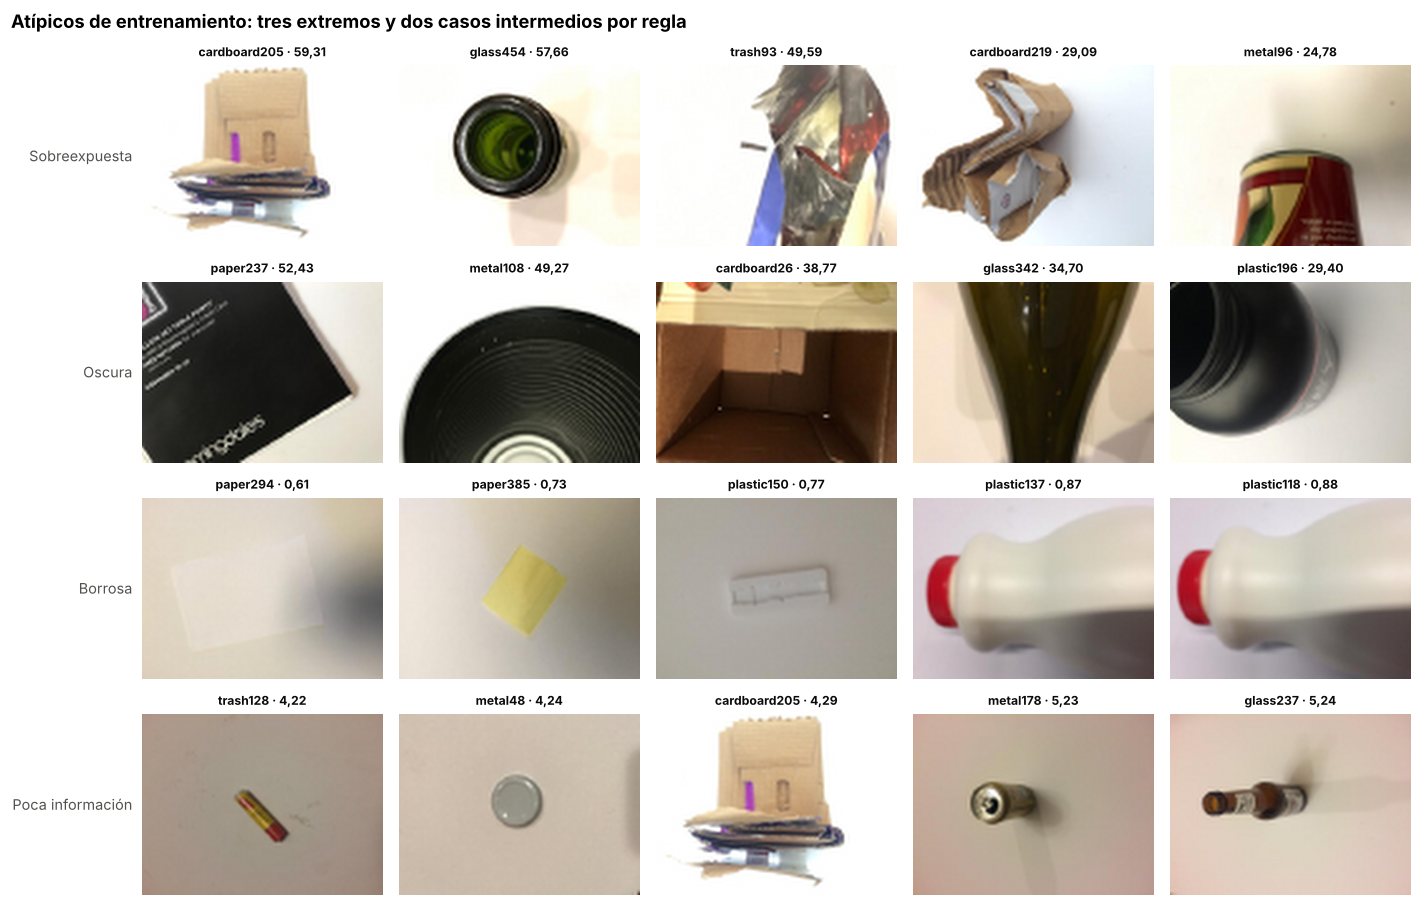

In [25]:
# @title Galería de atípicos
RULE_NAMES = {"sobreexpuesta": "Sobreexpuesta", "oscura": "Oscura", "borrosa": "Borrosa",
              "poca_informacion": "Poca información"}
order_keys = {"sobreexpuesta": ("sobreexpuesta", False), "oscura": ("oscura", False),
              "borrosa": ("nitidez", True), "poca_informacion": ("entropia", True)}
fig, axes = plt.subplots(len(OUTLIER_RULES), 5, figsize=(13, 8.4))
for r, (name, (column, ascending)) in enumerate(order_keys.items()):
    flagged = train.loc[train[f"atipico_{name}"]].sort_values(column, ascending=ascending)
    picks = pd.concat([flagged.head(3), flagged.iloc[len(flagged) // 2: len(flagged) // 2 + 2]]) if len(flagged) > 4 else flagged
    for c in range(5):
        ax = axes[r, c]
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if c < len(picks):
            item = picks.iloc[c]
            ax.imshow(THUMBS[item["ruta"]], interpolation="lanczos")
            ax.set_title(f"{Path(item['ruta']).stem} · {dec(item[column], 2)}", fontsize=8, color=INK)
    axes[r, 0].set_ylabel(RULE_NAMES[name], fontsize=9.5, rotation=0, ha="right", va="center", labelpad=6)
fig.suptitle("Atípicos de entrenamiento: tres extremos y dos casos intermedios por regla", fontsize=12,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [26]:
# @title Lectura y decisión sobre atípicos
display(Markdown(
    f"**Lectura y decisión sobre atípicos.** {miles(train['atipico'].sum())} imágenes de entrenamiento "
    f"({pct(train['atipico'].mean())}) cumplen al menos una regla. La revisión visual muestra que **son fotografías "
    "válidas**: fondos lavados por exceso de luz, primeros planos oscuros de latas, cajas y botellas, papel o plástico "
    "claros sobre fondo claro y primeros planos desenfocados (borrosas), y objetos muy pequeños (poca información). "
    "Ninguna está corrupta ni es ajena a las seis clases. Tampoco se distribuyen al azar: "
    f"`{by_class_flags['% de la clase'].idxmax()}` concentra la mayor proporción ({dec(by_class_flags['% de la clase'].max(), 1)} %), "
    "así que eliminarlas quitaría justamente los casos difíciles de ciertas clases y haría la evaluación más optimista.\n\n"
    "**Decisión:** se **conservan todas** con su etiqueta y se **marcan** en el manifiesto (`atipico_*`) para "
    "analizar errores por condición en la fase 5. Su existencia justifica aumentos moderados de brillo y contraste "
    "en entrenamiento (sección 2.4), para que el modelo no dependa de una exposición particular."
))

**Lectura y decisión sobre atípicos.** 98 imágenes de entrenamiento (5,5 %) cumplen al menos una regla. La revisión visual muestra que **son fotografías válidas**: fondos lavados por exceso de luz, primeros planos oscuros de latas, cajas y botellas, papel o plástico claros sobre fondo claro y primeros planos desenfocados (borrosas), y objetos muy pequeños (poca información). Ninguna está corrupta ni es ajena a las seis clases. Tampoco se distribuyen al azar: `glass` concentra la mayor proporción (8,5 %), así que eliminarlas quitaría justamente los casos difíciles de ciertas clases y haría la evaluación más optimista.

**Decisión:** se **conservan todas** con su etiqueta y se **marcan** en el manifiesto (`atipico_*`) para analizar errores por condición en la fase 5. Su existencia justifica aumentos moderados de brillo y contraste en entrenamiento (sección 2.4), para que el modelo no dependa de una exposición particular.

## 2. Limpieza y preparación de los datos
---

### 2.1 Resumen de decisiones de limpieza

Cada decisión responde a una evidencia de la sección 1. Los datos descargados no se modifican: las exclusiones y reasignaciones quedan registradas en el manifiesto.

In [27]:
# @title 2.1 Tabla de decisiones de limpieza
decisions = pd.DataFrame([
    ("Archivos ilegibles, vacíos o faltantes", f"{int(raw['error'].ne('').sum())} ilegibles; 0 faltantes (1.2.1)",
     "Ninguna acción; el control queda automatizado", "Sin cambios"),
    ("Píxeles idénticos con etiquetas distintas", f"{len(conflict_hashes)} grupos, {len(conflicts)} archivos (fase 1)",
     "Excluir todas las copias, sin reetiquetar", f"{miles(len(usable))} imágenes utilizables"),
    ("Copias exactas con la misma etiqueta", "0 casos", "Regla vigente: conservar una", "Sin cambios"),
    ("Casi duplicados entre particiones", f"{int((same_class & crosses & (pair_dist <= NEAR_DUP_THRESHOLD)).sum())} pares de la misma clase (1.2.2)",
     f"Agrupar misma clase con distancia ≤ {NEAR_DUP_THRESHOLD}; grupos que cruzan → entrenamiento",
     f"{len(moved)} imágenes reasignadas"),
    ("Atípicos de exposición, nitidez o contenido", f"{miles(train['atipico'].sum())} en entrenamiento (1.5)",
     "Conservar y marcar; aumentos de brillo y contraste", "Marcas `atipico_*`"),
    ("Desbalance de clases", f"razón {dec(train_counts.max() / train_counts.min())}:1 (1.3.2)",
     "Pesos por clase solo con entrenamiento; F1 macro", "Pesos en 2.7"),
    ("Fondo asociado a la clase", f"ε² = {dec(bg_eps, 3)} en calidez del borde (1.4)",
     "Ganancia aleatoria por canal en entrenamiento; vigilar en errores", "Aumento de color leve"),
    ("Relación de aspecto 4:3", f"mediana de {dec(train['energia_lateral'].median(), 1)} % de estructura en franjas laterales (1.3.5)",
     "Redimensionar a 160 × 120 conservando proporción y rellenar hasta 160 × 160", "Sin pérdida de encuadre"),
], columns=["Problema", "Evidencia", "Decisión", "Efecto"])
display(decisions.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Problema,Evidencia,Decisión,Efecto
"Archivos ilegibles, vacíos o faltantes",0 ilegibles; 0 faltantes (1.2.1),Ninguna acción; el control queda automatizado,Sin cambios
Píxeles idénticos con etiquetas distintas,"3 grupos, 6 archivos (fase 1)","Excluir todas las copias, sin reetiquetar",2.521 imágenes utilizables
Copias exactas con la misma etiqueta,0 casos,Regla vigente: conservar una,Sin cambios
Casi duplicados entre particiones,25 pares de la misma clase (1.2.2),Agrupar misma clase con distancia ≤ 10; grupos que cruzan → entrenamiento,26 imágenes reasignadas
"Atípicos de exposición, nitidez o contenido",98 en entrenamiento (1.5),Conservar y marcar; aumentos de brillo y contraste,Marcas `atipico_*`
Desbalance de clases,"razón 4,32:1 (1.3.2)",Pesos por clase solo con entrenamiento; F1 macro,Pesos en 2.7
Fondo asociado a la clase,"ε² = 0,197 en calidez del borde (1.4)",Ganancia aleatoria por canal en entrenamiento; vigilar en errores,Aumento de color leve
Relación de aspecto 4:3,"mediana de 10,9 % de estructura en franjas laterales (1.3.5)",Redimensionar a 160 × 120 conservando proporción y rellenar hasta 160 × 160,Sin pérdida de encuadre


### 2.2 Redimensionado: relleno frente a recorte

Las redes esperan entradas cuadradas de 160 × 160 (decisión de la fase 1, adecuada para MobileNetV2 y liviana para la CNN). Una imagen de 512 × 384 admite tres opciones: **deformarla** (cambia la forma de botellas y latas), **recortar el centro** (pierde las franjas laterales) o **reducirla conservando la proporción y rellenar** las franjas superior e inferior (*letterbox*). La evidencia de 1.3.5 favorece la tercera opción, porque el recorte eliminaría contenido justamente en primeros planos y objetos alargados.

,mediana (%),percentil 90 (%),% de imágenes con ≥ 20 % de estructura recortada
clase,,,
Cartón,22.2,31.4,62.9
Vidrio,10.4,22.1,15.1
Metal,6.7,20.8,11.3
Papel,11.3,23.1,14.9
Plástico,8.3,23.8,14.2
Residual,6.3,16.6,5.1


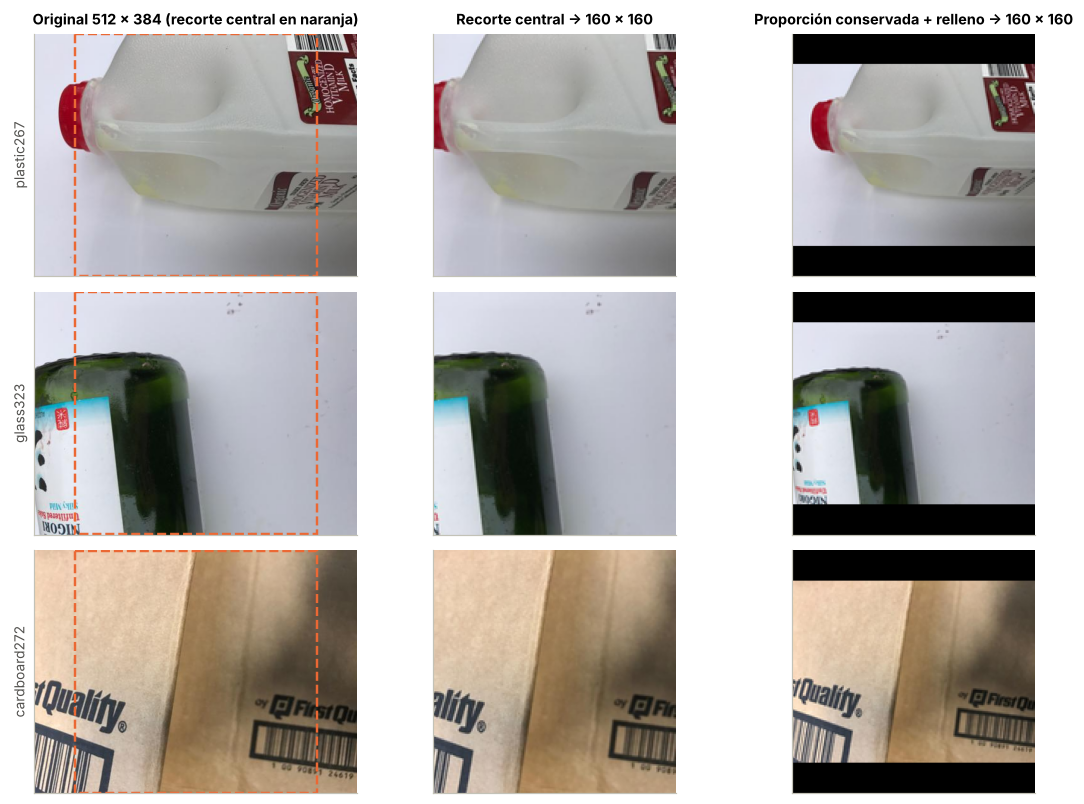

In [28]:
# @title 2.2 Estructura que perdería un recorte central
lateral_loss = train.groupby("clase")["energia_lateral"].agg(
    mediana="median", p90=lambda s: s.quantile(0.9), pierde_20=lambda s: 100 * (s >= 20).mean()).reindex(CLASSES)
lateral_loss.columns = ["mediana (%)", "percentil 90 (%)", "% de imágenes con ≥ 20 % de estructura recortada"]
display(lateral_loss.rename(index=LABEL_ES).round(1))

examples = [train.loc[train["clase"].eq(c)].sort_values("energia_lateral").iloc[-k]["ruta"]
            for c, k in [("plastic", 1), ("glass", 1), ("cardboard", 5)]]
fig, axes = plt.subplots(len(examples), 3, figsize=(10.5, 7.4))
for r, route in enumerate(examples):
    with Image.open(DATA_DIR / route) as picture:
        rgb = picture.convert("RGB")
    axes[r, 0].imshow(rgb)
    axes[r, 0].add_patch(Rectangle((64, 0), 384, 383, fill=False, ec="#eb6834", lw=1.6, ls="--"))
    axes[r, 1].imshow(rgb.crop((64, 0, 448, 384)).resize((160, 160), Image.Resampling.LANCZOS))
    letterbox = Image.new("RGB", (160, 160))
    letterbox.paste(rgb.resize((160, 120), Image.Resampling.LANCZOS), (0, 20))
    axes[r, 2].imshow(letterbox)
    axes[r, 0].set_ylabel(Path(route).stem, fontsize=9)
for ax, title in zip(axes[0], ["Original 512 × 384 (recorte central en naranja)",
                               "Recorte central → 160 × 160", "Proporción conservada + relleno → 160 × 160"]):
    ax.set_title(title, fontsize=9.5)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

**Decisión:** reducir cada imagen a **160 × 120** con filtro Lanczos (antialiasing) y rellenar con 20 filas negras arriba y abajo hasta **160 × 160**. Las bandas son idénticas para todas las clases, así que no aportan información de la etiqueta; el costo es que un 25 % del lienzo no tiene contenido. La alternativa de usar entradas rectangulares de 160 × 120 se deja documentada para la fase 3 si el tiempo de entrenamiento lo exige.

### 2.3 Caché en memoria: decodificar una sola vez

Decodificar el JPEG completo en cada época es la parte más costosa de la entrada. Como el redimensionado es determinista, se hace **una sola vez**: el decodificador JPEG de Pillow reduce a la mitad durante la propia decodificación (`draft`), luego se aplica Lanczos hasta 160 × 120 y el resultado se guarda como `uint8`. Los aumentos aleatorios, que sí cambian en cada época, se aplican después sobre la caché.

In [29]:
CONTENT_HW = (120, 160)                       # alto, ancho: conserva 4:3
IMG_SIZE = 160
PAD_TOP = (IMG_SIZE - CONTENT_HW[0]) // 2     # 20 filas de relleno arriba y abajo
CLASS_INDEX = {c: i for i, c in enumerate(CLASSES)}


def load_resized(relative):
    """Decodifica a escala 1/2 (DCT del JPEG) y reduce con Lanczos a 160 × 120 en uint8."""
    with Image.open(DATA_DIR / relative) as image:
        image.draft("RGB", (CONTENT_HW[1], CONTENT_HW[0]))
        rgb = image.convert("RGB")
        return np.asarray(rgb.resize((CONTENT_HW[1], CONTENT_HW[0]), Image.Resampling.LANCZOS), dtype=np.uint8)


t0 = time.perf_counter()
with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:
    X_all = np.stack(list(pool.map(load_resized, usable["ruta"])))
cache_seconds = time.perf_counter() - t0
y_all = usable["clase"].map(CLASS_INDEX).to_numpy(np.int32)
CACHE = {split: (X_all[(usable["particion"] == split).to_numpy()], y_all[(usable["particion"] == split).to_numpy()])
         for split in SPLITS}

channel_mean = CACHE["entrenamiento"][0].reshape(-1, 3).mean(axis=0)
channel_std = CACHE["entrenamiento"][0].reshape(-1, 3).std(axis=0)
display(pd.DataFrame({"imágenes": {SPLIT_ES[s]: len(CACHE[s][1]) for s in SPLITS},
                      "forma": {SPLIT_ES[s]: str(CACHE[s][0].shape) for s in SPLITS},
                      "MB en memoria": {SPLIT_ES[s]: round(CACHE[s][0].nbytes / 1e6, 1) for s in SPLITS}}))
print(f"Caché construida en {cache_seconds:.1f} s · {X_all.nbytes / 1e6:.0f} MB "
      f"(frente a {len(usable) * 512 * 384 * 3 / 1e6:.0f} MB si se guardaran las imágenes completas decodificadas)")
print("Media por canal RGB en entrenamiento (0-255):", np.round(channel_mean, 1),
      "| desviación:", np.round(channel_std, 1))

,imágenes,forma,MB en memoria
Entrenamiento,1798,"(1798, 120, 160, 3)",103.6
Validación,360,"(360, 120, 160, 3)",20.7
Prueba,363,"(363, 120, 160, 3)",20.9


Caché construida en 2.4 s · 145 MB (frente a 1487 MB si se guardaran las imágenes completas decodificadas)
Media por canal RGB en entrenamiento (0-255): [171.4 163.1 154.2] | desviación: [52.8 53.  58.8]


### 2.4 Pipeline de entrada con `tf.data` y aumentos solo en entrenamiento

El pipeline sigue las recomendaciones de rendimiento de TensorFlow [10]: los datos salen de la caché en memoria, se barajan en cada época, se agrupan en lotes **antes** de transformar (operaciones vectorizadas), se transforman en paralelo (`AUTOTUNE`) y se precargan (`prefetch`) para que la CPU prepare el siguiente lote mientras la GPU entrena.

| Aumento (solo entrenamiento) | Parámetro | Justificación con los datos |
|---|---|---|
| Reflexión horizontal | 50 % | La categoría del material no depende de la orientación izquierda-derecha |
| Rotación | ± 0,04 vueltas (≈ ± 14°), relleno por reflexión | Objetos fotografiados en ángulos variados; se aplica antes del relleno negro para no rotar las bandas |
| Zoom | ± 10 % | Variación del tamaño aparente (objetos pequeños frente a primeros planos) |
| Brillo | ± 10 % del rango | Atípicos de exposición (1.5) |
| Contraste | factor en [0,85; 1,15] | Plástico y vidrio de bajo contraste (1.3) |
| Ganancia por canal (balance de blancos) | ± 6 % por canal | Reduce el atajo del tono del fondo por clase (1.3.6 y 1.4) sin cambiar el color propio del material |

Los parámetros son moderados a propósito: aumentos demasiado fuertes pueden convertir un vidrio verde en otro material. Su efecto se medirá en validación en la fase 4 (con y sin la ganancia por canal).

**Escala por modelo, aplicada una sola vez:** la CNN recibe píxeles en [0, 1]; MobileNetV2 recibe x/127,5 − 1, en [−1, 1], que es exactamente su `preprocess_input` [11]. Los modelos de la fase 3 **no** deben volver a normalizar.

In [30]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32
AUGMENTATION = {"reflexion": "horizontal", "rotacion": 0.04, "zoom": 0.10, "brillo": 0.10,
                "contraste": 0.15, "ganancia_canal": 0.06}

augmenter = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(AUGMENTATION["reflexion"], seed=SEED),
    tf.keras.layers.RandomRotation(AUGMENTATION["rotacion"], fill_mode="reflect", seed=SEED + 1),
    tf.keras.layers.RandomZoom(AUGMENTATION["zoom"], fill_mode="reflect", seed=SEED + 2),
    tf.keras.layers.RandomBrightness(AUGMENTATION["brillo"], value_range=(0, 255), seed=SEED + 3),
    tf.keras.layers.RandomContrast(AUGMENTATION["contraste"], seed=SEED + 4),
], name="aumentos_entrenamiento")


def augment_batch(images):
    """Aumentos geométricos y fotométricos sobre un lote float32 en [0, 255], antes del relleno."""
    images = augmenter(images, training=True)
    g = AUGMENTATION["ganancia_canal"]
    gains = tf.random.uniform((tf.shape(images)[0], 1, 1, 3), 1 - g, 1 + g)
    return tf.clip_by_value(images * gains, 0.0, 255.0)


def pad_and_scale(images, scale):
    """Relleno a 160 × 160 y escala propia de cada arquitectura."""
    images = tf.image.pad_to_bounding_box(images, PAD_TOP, 0, IMG_SIZE, IMG_SIZE)
    if scale == "cnn":
        return images / 255.0
    if scale == "mobilenet":
        return images / 127.5 - 1.0
    raise ValueError("scale debe ser 'cnn' o 'mobilenet'")


def make_dataset(split, scale="cnn", batch_size=BATCH_SIZE, augment=None, shuffle=None):
    """Dataset listo para Keras. Aumentos y barajado solo en entrenamiento, salvo indicación explícita."""
    augment = (split == "entrenamiento") if augment is None else augment
    shuffle = (split == "entrenamiento") if shuffle is None else shuffle
    if augment and split != "entrenamiento":
        raise ValueError("Los aumentos solo se aplican al entrenamiento.")
    images, labels = CACHE[split]
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        ds = ds.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)

    def transform(x, y):
        x = tf.cast(x, tf.float32)
        if augment:
            x = augment_batch(x)
        return pad_and_scale(x, scale), y

    return ds.map(transform, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


datasets = {(split, scale): make_dataset(split, scale) for split in ("entrenamiento", "validacion")
            for scale in ("cnn", "mobilenet")}
print(datasets[("entrenamiento", "cnn")].element_spec)

(TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


### 2.5 Verificación visual y numérica del pipeline

Se recorre el mismo código que usarán los modelos: una imagen de entrenamiento pasa por la caché, el relleno y siete aumentos distintos; luego se muestra un lote completo tal como lo recibirá la red.

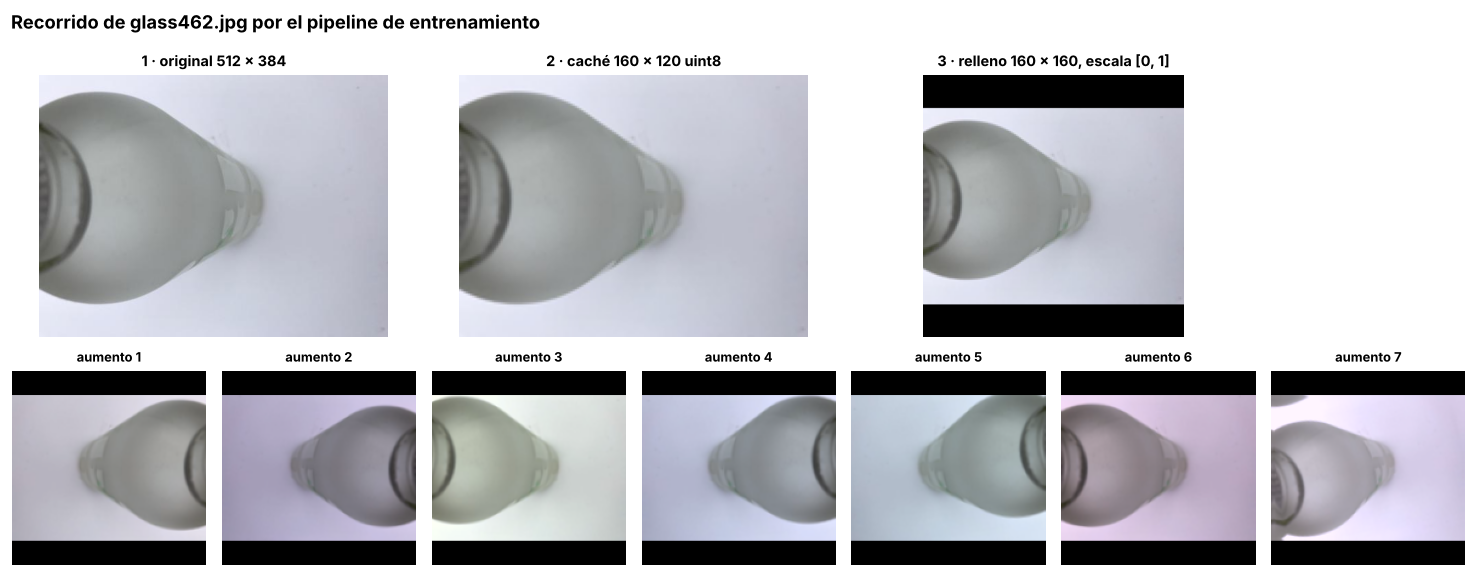

In [31]:
# @title 2.5 Verificación visual de los aumentos
example = train.loc[train["clase"].eq("glass")].sort_values("energia_lateral").iloc[-3]
idx = int(np.where(usable["ruta"].to_numpy() == example["ruta"])[0][0])
cached = X_all[idx]
original = np.asarray(Image.open(DATA_DIR / example["ruta"]).convert("RGB"))
final = pad_and_scale(tf.cast(cached[None], tf.float32), "cnn")[0].numpy()
augmented = pad_and_scale(augment_batch(tf.cast(np.repeat(cached[None], 7, axis=0), tf.float32)), "cnn").numpy()

fig = plt.figure(figsize=(13.5, 5.6))
grid = fig.add_gridspec(2, 7, height_ratios=[1, 1])
steps = [(original, "1 · original 512 × 384"), (cached, "2 · caché 160 × 120 uint8"),
         (final, "3 · relleno 160 × 160, escala [0, 1]")]
for k, (img, title) in enumerate(steps):
    ax = fig.add_subplot(grid[0, 2 * k: 2 * k + 2] if k < 3 else grid[0, 6])
    ax.imshow(img)
    ax.set_title(title, fontsize=9.5)
    ax.axis("off")
for k in range(7):
    ax = fig.add_subplot(grid[1, k])
    ax.imshow(augmented[k])
    ax.set_title(f"aumento {k + 1}", fontsize=8.5)
    ax.axis("off")
fig.suptitle(f"Recorrido de {Path(example['ruta']).name} por el pipeline de entrenamiento", fontsize=12,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

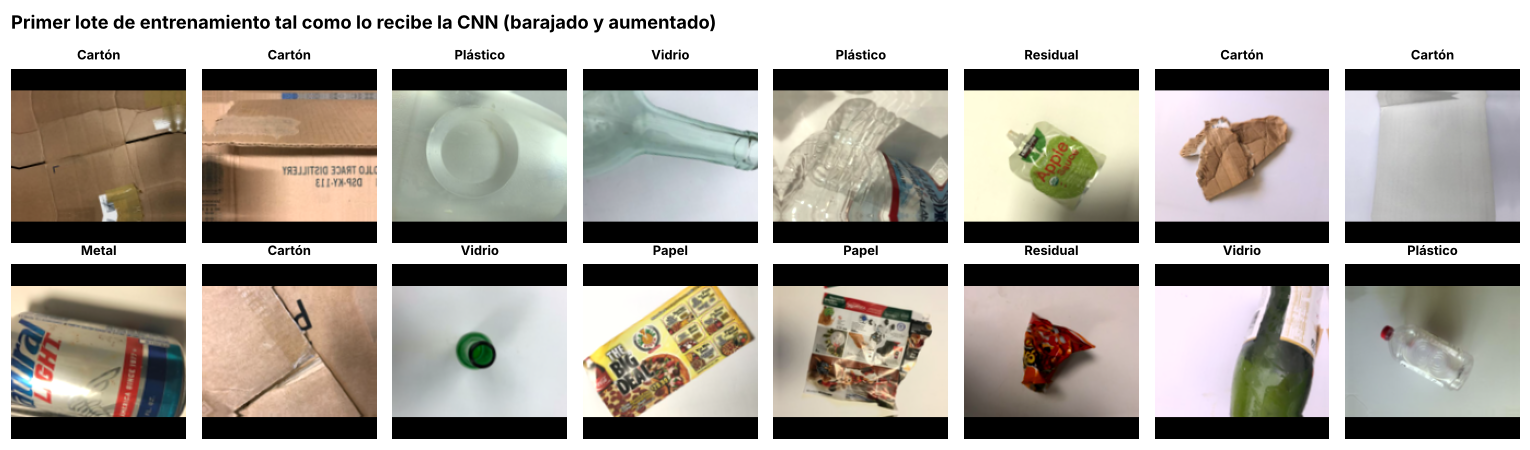

,partición,escala,lote,tipo,mínimo,máximo,etiquetas
0,Entrenamiento,cnn,"(32, 160, 160, 3)",float32,0.0,1.0,int32
1,Entrenamiento,mobilenet,"(32, 160, 160, 3)",float32,-1.0,1.0,int32
2,Validación,cnn,"(32, 160, 160, 3)",float32,0.0,1.0,int32
3,Validación,mobilenet,"(32, 160, 160, 3)",float32,-1.0,1.0,int32


Validación sin aumentos (dos lecturas idénticas): True
Escala MobileNetV2 idéntica a keras.applications.mobilenet_v2.preprocess_input: True


In [32]:
# @title Lote de entrenamiento y controles de escala
batch_x, batch_y = next(iter(datasets[("entrenamiento", "cnn")]))
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, image, label in zip(axes.ravel(), batch_x.numpy(), batch_y.numpy()):
    ax.imshow(image)
    ax.set_title(LABEL_ES[CLASSES[label]], fontsize=8.5)
    ax.axis("off")
fig.suptitle("Primer lote de entrenamiento tal como lo recibe la CNN (barajado y aumentado)", fontsize=12,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plt.show()

shape_rows = []
for (split, scale), ds in datasets.items():
    x, y = next(iter(ds))
    shape_rows.append({"partición": SPLIT_ES[split], "escala": scale, "lote": tuple(x.shape), "tipo": x.dtype.name,
                       "mínimo": round(float(tf.reduce_min(x)), 3), "máximo": round(float(tf.reduce_max(x)), 3),
                       "etiquetas": y.dtype.name})
display(pd.DataFrame(shape_rows))

val_first = [next(iter(make_dataset("validacion", "cnn")))[0].numpy() for _ in range(2)]
val_deterministic = bool(np.array_equal(val_first[0], val_first[1]))
reference = tf.keras.applications.mobilenet_v2.preprocess_input(tf.cast(X_all[:16], tf.float32)).numpy()
ours = (tf.cast(X_all[:16], tf.float32) / 127.5 - 1.0).numpy()
mobilenet_matches = bool(np.allclose(reference, ours, atol=1e-6))
print("Validación sin aumentos (dos lecturas idénticas):", val_deterministic)
print("Escala MobileNetV2 idéntica a keras.applications.mobilenet_v2.preprocess_input:", mobilenet_matches)

### 2.6 Eficiencia del pipeline

Se mide el rendimiento real (imágenes por segundo) de tres épocas completas de entrenamiento con aumentos y se compara con una alternativa ingenua que lee y decodifica cada JPEG completo en cada época. Se reporta la mediana de las tres épocas para reducir el ruido de medición; los valores dependen del número de núcleos de CPU disponibles.

In [33]:
# @title 2.6 Medición del rendimiento del pipeline
def throughput(ds, epochs=3):
    """Recorre el dataset completo y devuelve imágenes por segundo de cada época."""
    rates = []
    for _ in range(epochs):
        t0, n = time.perf_counter(), 0
        for _, y in ds:
            n += int(y.shape[0])
        rates.append(n / (time.perf_counter() - t0))
    return rates


train_paths = [str(DATA_DIR / r) for r in usable.loc[usable["particion"].eq("entrenamiento"), "ruta"]]


def decode_full(path, label):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(image, CONTENT_HW, antialias=True), label


naive = (tf.data.Dataset.from_tensor_slices((train_paths, CACHE["entrenamiento"][1]))
         .shuffle(len(train_paths), seed=SEED).map(decode_full, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
         .map(lambda x, y: (pad_and_scale(augment_batch(x), "cnn"), y), num_parallel_calls=AUTOTUNE)
         .prefetch(AUTOTUNE))

rates = {"Caché en memoria + aumentos por lote (propuesto)": throughput(datasets[("entrenamiento", "cnn")]),
         "Leer y decodificar JPEG en cada época": throughput(naive)}
efficiency = pd.DataFrame({name: {f"época {k + 1} (img/s)": v for k, v in enumerate(r)}
                           | {"mediana (img/s)": float(np.median(r))} for name, r in rates.items()}).T.round(0)
efficiency["segundos por época"] = (len(train_paths) / efficiency["mediana (img/s)"]).round(2)
display(efficiency)
speedup = efficiency.iloc[0]["mediana (img/s)"] / efficiency.iloc[1]["mediana (img/s)"]
print(f"Aceleración del pipeline propuesto: {speedup:.1f}× en {os.cpu_count()} núcleos de CPU")

,época 1 (img/s),época 2 (img/s),época 3 (img/s),mediana (img/s),segundos por época
Caché en memoria + aumentos por lote (propuesto),557.0,348.0,556.0,556.0,3.23
Leer y decodificar JPEG en cada época,332.0,346.0,175.0,332.0,5.42


Aceleración del pipeline propuesto: 1.7× en 2 núcleos de CPU


### 2.7 Pesos por clase (solo entrenamiento)

Para compensar el desbalance sin duplicar ni descartar imágenes se calculan pesos inversamente proporcionales a la frecuencia, w_c = n / (k · n_c), con los conteos de **entrenamiento** [12]. Con estos pesos cada clase aporta lo mismo a la función de pérdida. Se usarán en la fase 4 si mejoran el F1 macro en validación, como se planeó en la fase 1.

In [34]:
weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=CACHE["entrenamiento"][1])
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(weights)}
weights_table = pd.DataFrame({"imágenes": train_counts.values, "peso": weights.round(3),
                              "aporte efectivo (n × peso)": (train_counts.values * weights).round(1)},
                             index=[LABEL_ES[c] for c in CLASSES])
display(weights_table)
print("class_weight para Keras:", {k: round(v, 3) for k, v in CLASS_WEIGHT.items()})

,imágenes,peso,aporte efectivo (n × peso)
Cartón,286,1.048,299.7
Vidrio,352,0.851,299.7
Metal,293,1.023,299.7
Papel,423,0.708,299.7
Plástico,346,0.866,299.7
Residual,98,3.058,299.7


class_weight para Keras: {0: 1.048, 1: 0.851, 2: 1.023, 3: 0.708, 4: 0.866, 5: 3.058}


## 3. Líneas base en validación
---

Antes de entrenar redes conviene saber qué se logra **sin aprendizaje profundo**. Se comparan tres referencias, todas ajustadas con entrenamiento y evaluadas en validación:

1. **Mayoritaria:** predice siempre la clase más frecuente de entrenamiento (la referencia mínima de la fase 1).
2. **Solo fondo:** regresión logística con seis descriptores del borde (brillo, calidez, variación y RGB del borde). Mide cuánta información de la etiqueta está en el fondo y la iluminación, es decir, el tamaño del atajo disponible.
3. **Descriptores globales:** regresión logística regularizada con los 16 descriptores de la sección 1.3. Es la referencia que una CNN debería superar con claridad.

Las regresiones usan pesos balanceados y estandarización, sin ajuste de hiperparámetros.

In [35]:
# @title 3. Líneas base en validación
val = usable.loc[usable["particion"].eq("validacion")].copy()
BACKGROUND_COLS = ["borde_brillo", "borde_calidez", "borde_variacion", "borde_R", "borde_G", "borde_B"]
baselines = {
    f"Mayoritaria (siempre {train_counts.idxmax()})": (DummyClassifier(strategy="most_frequent"), ["brillo"]),
    "Solo fondo (6 descriptores del borde)": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")), BACKGROUND_COLS),
    "Descriptores globales (16)": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced")), ANALYSIS_COLS),
}
rows, predictions = [], {}
for name, (model, cols) in baselines.items():
    model.fit(train[cols], train["clase"])
    pred = model.predict(val[cols])
    predictions[name] = pred
    recalls = recall_score(val["clase"], pred, labels=CLASSES, average=None, zero_division=0)
    rows.append({"línea base": name, "accuracy": accuracy_score(val["clase"], pred),
                 "F1 macro": f1_score(val["clase"], pred, labels=CLASSES, average="macro", zero_division=0),
                 "recall mínimo": recalls.min(), "clase con menor recall": CLASSES[int(recalls.argmin())],
                 "recall trash": recalls[CLASSES.index("trash")]})
baseline_table = pd.DataFrame(rows).set_index("línea base")
display(baseline_table.style.format({c: "{:.3f}" for c in ["accuracy", "F1 macro", "recall mínimo", "recall trash"]}))

,accuracy,F1 macro,recall mínimo,clase con menor recall,recall trash
línea base,,,,,
Mayoritaria (siempre paper),0.231,0.062,0.000,cardboard,0.000
Solo fondo (6 descriptores del borde),0.433,0.403,0.122,glass,0.579
Descriptores globales (16),0.547,0.528,0.378,glass,0.579


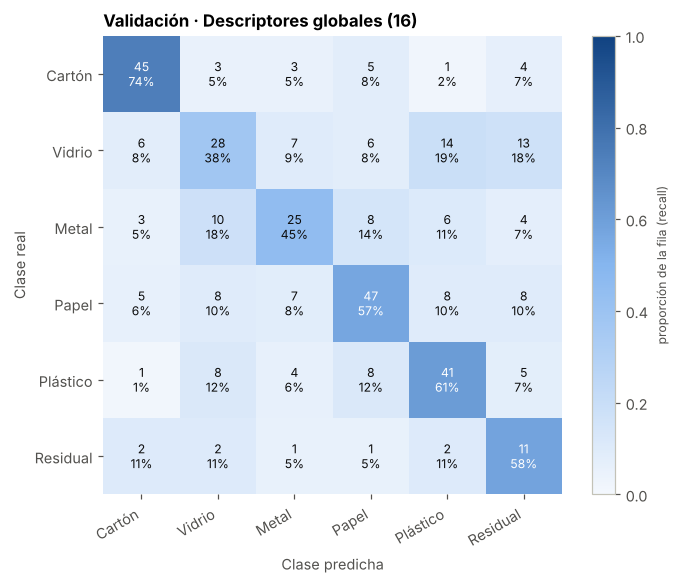

In [36]:
# @title Matriz de confusión de la mejor línea base
best_name = "Descriptores globales (16)"
cm = confusion_matrix(val["clase"], predictions[best_name], labels=CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(cm_norm, cmap=SEQUENTIAL, vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm[i, j]}\n{cm_norm[i, j]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if cm_norm[i, j] > 0.55 else INK)
labels = [LABEL_ES[c] for c in CLASSES]
ax.set_xticks(range(len(CLASSES)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES)), labels)
ax.set(xlabel="Clase predicha", ylabel="Clase real")
ax.spines[:].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.045)
cbar.set_label("proporción de la fila (recall)", fontsize=8)
ax.set_title(f"Validación · {best_name}", loc="left")
fig.tight_layout()
plt.show()

In [37]:
# @title Lectura de las líneas base
bt = baseline_table
maj, bg, glob = bt.index
off_values = cm.copy()
np.fill_diagonal(off_values, 0)
off_diag = pd.DataFrame(off_values, index=CLASSES, columns=CLASSES)
worst_pair = off_diag.stack().idxmax()
display(Markdown(
    f"**Lectura de las líneas base.** La referencia mayoritaria obtiene F1 macro {dec(bt.loc[maj, 'F1 macro'], 3)} "
    f"con accuracy {dec(bt.loc[maj, 'accuracy'], 3)}: confirma que la accuracy sola no sirve. **Solo con el color y el "
    f"brillo del fondo** se alcanza F1 macro {dec(bt.loc[bg, 'F1 macro'], 3)}, unas "
    f"{dec(bt.loc[bg, 'F1 macro'] / max(bt.loc[maj, 'F1 macro'], 1e-9), 0)} veces la mayoritaria, sin mirar el objeto: es "
    "la medida del atajo disponible. Los descriptores globales llegan a F1 macro "
    f"{dec(bt.loc[glob, 'F1 macro'], 3)} (recall mínimo {dec(bt.loc[glob, 'recall mínimo'], 3)} en "
    f"`{bt.loc[glob, 'clase con menor recall']}`); la confusión más frecuente es `{worst_pair[0]}` → `{worst_pair[1]}` "
    f"({off_diag.loc[worst_pair]} imágenes).\n\n"
    "**Implicaciones para las fases 3 y 4:** (1) la meta de F1 macro ≥ 0,80 está muy por encima de lo que logran los "
    "estadísticos globales, así que exige representaciones de forma y textura; (2) cualquier modelo debe superar "
    f"claramente {dec(bt.loc[glob, 'F1 macro'], 2)} en validación para justificar su complejidad; (3) en el análisis de "
    "errores se revisará si los aciertos dependen del fondo, por ejemplo comparando el desempeño en imágenes con "
    "fondos atípicos para su clase."
))

**Lectura de las líneas base.** La referencia mayoritaria obtiene F1 macro 0,062 con accuracy 0,231: confirma que la accuracy sola no sirve. **Solo con el color y el brillo del fondo** se alcanza F1 macro 0,403, unas 6 veces la mayoritaria, sin mirar el objeto: es la medida del atajo disponible. Los descriptores globales llegan a F1 macro 0,528 (recall mínimo 0,378 en `glass`); la confusión más frecuente es `glass` → `plastic` (14 imágenes).

**Implicaciones para las fases 3 y 4:** (1) la meta de F1 macro ≥ 0,80 está muy por encima de lo que logran los estadísticos globales, así que exige representaciones de forma y textura; (2) cualquier modelo debe superar claramente 0,53 en validación para justificar su complejidad; (3) en el análisis de errores se revisará si los aciertos dependen del fondo, por ejemplo comparando el desempeño en imágenes con fondos atípicos para su clase.

## 4. Controles automáticos y trazabilidad
---

Los controles se ejecutan en cada corrida; si alguno falla, el notebook se detiene antes de guardar archivos.

In [38]:
# @title 4. Controles automáticos
val_f1 = set(usable.loc[usable["particion_fase1"].eq("validacion"), "ruta"])
test_f1 = set(usable.loc[usable["particion_fase1"].eq("prueba"), "ruta"])
checks = {
    "Reconstrucción de la fase 1 verificada (0.4)": all(checks_f1.values()),
    "Sin valores faltantes ni infinitos en descriptores": bool(np.isfinite(usable[descriptor_cols].to_numpy()).all()),
    "Cada grupo de casi duplicados en una sola partición": usable.groupby("grupo")["particion"].nunique().max() == 1,
    "Validación solo pierde imágenes respecto de la fase 1": set(val["ruta"]) <= val_f1,
    "Prueba solo pierde imágenes respecto de la fase 1":
        set(usable.loc[usable["particion"].eq("prueba"), "ruta"]) <= test_f1,
    "Las seis clases están en las tres particiones": bool(split_table.gt(0).all().all()),
    "Particiones cubren el conjunto utilizable": int(split_table.to_numpy().sum()) == len(usable),
    "Caché uint8 de forma (n, 120, 160, 3)": X_all.dtype == np.uint8 and X_all.shape[1:] == (120, 160, 3),
    "Lotes de 160 × 160 × 3 en float32": all(r["lote"][1:] == (160, 160, 3) and r["tipo"] == "float32" for r in shape_rows),
    "Escala CNN en [0, 1] y MobileNetV2 en [−1, 1]": all(
        (r["mínimo"] >= 0 and r["máximo"] <= 1) if r["escala"] == "cnn" else (r["mínimo"] >= -1 and r["máximo"] <= 1)
        for r in shape_rows),
    "Escala MobileNetV2 igual a preprocess_input": mobilenet_matches,
    "Validación determinista (sin aumentos)": val_deterministic,
    "Pesos por clase igualan el aporte de cada clase":
        bool(np.allclose(train_counts.values * weights, len(train) / len(CLASSES))),
    "Prueba no usada en análisis ni en líneas base": "prueba" not in set(train["particion"]) | set(val["particion"]),
}
check_table = pd.DataFrame({"control": checks.keys(), "resultado": ["OK" if v else "REVISAR" for v in checks.values()]})
display(check_table)
assert all(checks.values()), "Un control falló: revise antes de pasar a la fase 3."

,control,resultado
0,Reconstrucción de la fase 1 verificada (0.4),OK
1,Sin valores faltantes ni infinitos en descript...,OK
2,Cada grupo de casi duplicados en una sola part...,OK
3,Validación solo pierde imágenes respecto de la...,OK
4,Prueba solo pierde imágenes respecto de la fase 1,OK
5,Las seis clases están en las tres particiones,OK
6,Particiones cubren el conjunto utilizable,OK
7,"Caché uint8 de forma (n, 120, 160, 3)",OK
8,Lotes de 160 × 160 × 3 en float32,OK
9,"Escala CNN en [0, 1] y MobileNetV2 en [−1, 1]",OK


In [39]:
# @title Archivos de trazabilidad
manifest_cols = (["ruta", "clase", "particion", "particion_fase1", "grupo", "grupo_fase1", "bytes", "sha256",
                  "pixel_sha256", "phash", "atipico"] + flag_cols + descriptor_cols)
usable[manifest_cols].to_csv(REPORT_DIR / "manifiesto_fase2.csv", index=False)
moved[["ruta", "clase", "particion_fase1", "particion", "grupo"]].to_csv(REPORT_DIR / "reasignadas_fase2.csv", index=False)
baseline_table.to_csv(REPORT_DIR / "lineas_base_validacion.csv")

config = {
    "ejecutado_utc": datetime.now(timezone.utc).isoformat(),
    "fuente": source["nombre"], "url": source["url"], "zip_sha256": source["sha256"],
    "semilla": SEED, "versiones": versions, "clases": CLASSES,
    "huella_particion_fase1": FASE1_HUELLA,
    "casi_duplicados": {"umbral_phash": NEAR_DUP_THRESHOLD, "misma_clase": True,
                        "regla": "grupos que cruzan particiones pasan a entrenamiento",
                        "imagenes_reasignadas": int(len(moved))},
    "conteos_particiones": {s: int(split_table[s].sum()) for s in SPLITS},
    "conteos_por_clase": {s: {c: int(split_table.loc[c, s]) for c in CLASSES} for s in SPLITS},
    "entrada": {"contenido_alto_ancho": list(CONTENT_HW), "lienzo": [IMG_SIZE, IMG_SIZE, 3],
                "relleno_superior_inferior": PAD_TOP, "valor_relleno": 0, "redimensionado": "draft JPEG 1/2 + Lanczos"},
    "escalas": {"cnn": "x / 255 -> [0, 1]", "mobilenet": "x / 127.5 - 1 -> [-1, 1] (preprocess_input)"},
    "aumentos_entrenamiento": AUGMENTATION, "batch_size": BATCH_SIZE,
    "media_canales_entrenamiento": [round(float(v), 2) for v in channel_mean],
    "desviacion_canales_entrenamiento": [round(float(v), 2) for v in channel_std],
    "pesos_clase": {CLASSES[k]: round(v, 4) for k, v in CLASS_WEIGHT.items()},
    "lineas_base_validacion": {k: {m: round(float(v), 4) for m, v in row.items() if m != "clase con menor recall"}
                               for k, row in baseline_table.to_dict("index").items()},
    "atipicos_entrenamiento": {name: int(train[f"atipico_{name}"].sum()) for name in OUTLIER_RULES},
    "controles": {k: bool(v) for k, v in checks.items()},
}
(REPORT_DIR / "config_fase2.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")
print("Archivos generados en residuos_fase2/reportes:")
for path in sorted(REPORT_DIR.iterdir()):
    print(f"• {path.name} ({path.stat().st_size / 1024:.0f} KB)")

Archivos generados en residuos_fase2/reportes:
• config_fase2.json (4 KB)
• lineas_base_validacion.csv (0 KB)
• manifiesto_fase2.csv (1468 KB)
• reasignadas_fase2.csv (2 KB)


Los archivos anteriores permiten que la fase 3 reutilice exactamente las mismas particiones, parámetros y pesos. Para conservarlos entre sesiones de Colab basta con copiar la carpeta `reportes` a Google Drive.

## 5. Conclusiones de la fase 2
---


In [40]:
# @title 5. Conclusiones
sizes = split_table.sum()
display(Markdown(
    f"1. **Estructura:** {miles(len(raw))} imágenes JPEG RGB de 512 × 384 en seis carpetas-etiqueta "
    f"({dec(ARCHIVE.stat().st_size / 1e6)} MB comprimidos). No hay faltantes, archivos ilegibles, mezcla de formatos "
    "ni problemas de orientación o codificación.\n"
    f"2. **Duplicados:** además de los {len(conflicts)} archivos con etiquetas en conflicto ya excluidos, se encontraron "
    "fotos del mismo objeto repartidas entre particiones. Con la regla misma clase y distancia pHash ≤ "
    f"{NEAR_DUP_THRESHOLD}, {len(moved)} imágenes pasaron a entrenamiento. Partición final: "
    f"{miles(sizes['entrenamiento'])} / {miles(sizes['validacion'])} / {miles(sizes['prueba'])} imágenes, sin grupos "
    "que crucen particiones y con la prueba como subconjunto de la fase 1.\n"
    f"3. **Distribución:** objetivo categórico de seis clases con desbalance moderado "
    f"({dec(train_counts.max() / train_counts.min())}:1), concentrado en `trash`; se usarán F1 macro, recall por clase "
    "y pesos por clase calculados en entrenamiento.\n"
    "4. **Contenido visual:** saturación, contraste y encuadre distinguen parcialmente las clases. El fondo y la "
    f"iluminación también lo hacen (ε² = {dec(bg_eps, 3)} en la calidez del borde), un atajo que puede inflar el desempeño "
    "dentro de TrashNet sin generalizar. Se mitiga con aumentos de color y se vigilará en el análisis de errores.\n"
    f"5. **Atípicos:** {miles(train['atipico'].sum())} imágenes de entrenamiento con exposición, nitidez o contenido "
    "extremos; son casos reales y difíciles, se conservan y quedan marcados.\n"
    f"6. **Preprocesamiento:** caché de 160 × 120 en {dec(cache_seconds, 1)} s y {dec(X_all.nbytes / 1e6, 0)} MB, relleno a "
    f"160 × 160 sin perder encuadre, aumentos solo en entrenamiento y escala propia por modelo. El pipeline procesa "
    f"≈ {miles(efficiency.iloc[0]['mediana (img/s)'])} imágenes/s en CPU, {dec(speedup, 1)} veces la lectura directa de JPEG.\n"
    f"7. **Referencias para superar:** en validación, F1 macro {dec(bt.loc[maj, 'F1 macro'], 3)} (mayoritaria), "
    f"{dec(bt.loc[bg, 'F1 macro'], 3)} (solo fondo) y {dec(bt.loc[glob, 'F1 macro'], 3)} (descriptores globales)."
))

1. **Estructura:** 2.527 imágenes JPEG RGB de 512 × 384 en seis carpetas-etiqueta (42,83 MB comprimidos). No hay faltantes, archivos ilegibles, mezcla de formatos ni problemas de orientación o codificación.
2. **Duplicados:** además de los 6 archivos con etiquetas en conflicto ya excluidos, se encontraron fotos del mismo objeto repartidas entre particiones. Con la regla misma clase y distancia pHash ≤ 10, 26 imágenes pasaron a entrenamiento. Partición final: 1.798 / 360 / 363 imágenes, sin grupos que crucen particiones y con la prueba como subconjunto de la fase 1.
3. **Distribución:** objetivo categórico de seis clases con desbalance moderado (4,32:1), concentrado en `trash`; se usarán F1 macro, recall por clase y pesos por clase calculados en entrenamiento.
4. **Contenido visual:** saturación, contraste y encuadre distinguen parcialmente las clases. El fondo y la iluminación también lo hacen (ε² = 0,197 en la calidez del borde), un atajo que puede inflar el desempeño dentro de TrashNet sin generalizar. Se mitiga con aumentos de color y se vigilará en el análisis de errores.
5. **Atípicos:** 98 imágenes de entrenamiento con exposición, nitidez o contenido extremos; son casos reales y difíciles, se conservan y quedan marcados.
6. **Preprocesamiento:** caché de 160 × 120 en 2,4 s y 145 MB, relleno a 160 × 160 sin perder encuadre, aumentos solo en entrenamiento y escala propia por modelo. El pipeline procesa ≈ 556 imágenes/s en CPU, 1,7 veces la lectura directa de JPEG.
7. **Referencias para superar:** en validación, F1 macro 0,062 (mayoritaria), 0,403 (solo fondo) y 0,528 (descriptores globales).

### Próximos pasos (fase 3 · Diseño e implementación)

- Construir la CNN pequeña y MobileNetV2 con nueva cabeza sobre `make_dataset(split, scale="cnn" | "mobilenet")`, con entrada de 160 × 160 × 3 y **sin capas adicionales de normalización**.
- Ejecutar un ensayo corto de una época para medir el tiempo real por época en GPU y fijar el presupuesto de la fase 4.
- Mantener intactas las particiones de esta fase (`manifiesto_fase2.csv`, huella y reglas en `config_fase2.json`) y reservar la prueba para la fase 5.
- Planear en la fase 4 dos comparaciones acotadas en validación: con y sin pesos por clase, y con y sin la ganancia por canal.

## 6. Referencias
---

1. Thung, G. y Yang, M. (2016). *TrashNet: repositorio y descripción del conjunto de datos*. [GitHub](https://github.com/garythung/trashnet).
2. Thung, G. *TrashNet: distribución del autor en Hugging Face (revisión fijada)*. [Hugging Face](https://huggingface.co/datasets/garythung/trashnet/tree/94cd17ebfd6702bf62281d3c89f22ff649815b46).
3. Material del curso: *Instrucciones Proyecto aplicado – Fase 2* y notebook guía *Entendimiento y preparación de los datos*.
4. Notebook de la fase 1 del equipo: *Clasificación visual de residuos · Entendimiento del negocio y carga de datos*.
5. Hasler, D. y Süsstrunk, S. (2003). Measuring colourfulness in natural images. *Proc. SPIE 5007, Human Vision and Electronic Imaging VIII*.
6. Pech-Pacheco, J. L., Cristóbal, G., Chamorro-Martínez, J. y Fernández-Valdivia, J. (2000). Diatom autofocusing in brightfield microscopy: a comparative study. *Proc. 15th International Conference on Pattern Recognition (ICPR)*.
7. Tomczak, M. y Tomczak, E. (2014). The need to report effect size estimates revisited. *Trends in Sport Sciences*, 21(1), 19–25.
8. Zauner, C. (2010). *Implementation and benchmarking of perceptual image hash functions*. Tesis de maestría, Upper Austria University of Applied Sciences.
9. Geirhos, R. et al. (2020). Shortcut learning in deep neural networks. *Nature Machine Intelligence*, 2, 665–673.
10. TensorFlow. *Better performance with the tf.data API*. [Guía oficial](https://www.tensorflow.org/guide/data_performance).
11. Keras. *MobileNet, MobileNetV2 y MobileNetV3: preprocess_input*. [Documentación](https://keras.io/api/applications/mobilenet/).
12. scikit-learn. *compute_class_weight*. [Documentación](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html).
13. TensorFlow. *Data augmentation*. [Tutorial oficial](https://www.tensorflow.org/tutorials/images/data_augmentation).